# Árvore de Decisão - Exercício _Water Quality_

### Preparação do ambiente

In [114]:
rm(list=ls())
library(repr)
library(readr)
library(corrplot)

In [115]:
grafdim <- function(x=11, y=9) { 
    options(repr.plot.width=x, repr.plot.height=y) 
}
grafdim()

## Dados

Os dados são de [_Water Quality_](https://www.kaggle.com/datasets/adityakadiwal/water-potability), contendo observações com diversos valores para propriedades químicas da água com a finalidade de avaliar sua potabilidade: se é potável (`potability` = 1) ou não (`potability` = 0).

In [116]:
qa <- read.csv(unzip("Water_Quality.zip","water_potability.csv"))
file.remove("water_potability.csv")

[1] TRUE

In [117]:
paste("Há ",nrow(qa)," registros no conjunto de dados")

[1] "Há  3276  registros no conjunto de dados"

In [118]:
str(qa)

'data.frame':	3276 obs. of  10 variables:
 $ ph             : num  NA 3.72 8.1 8.32 9.09 ...
 $ Hardness       : num  205 129 224 214 181 ...
 $ Solids         : num  20791 18630 19910 22018 17979 ...
 $ Chloramines    : num  7.3 6.64 9.28 8.06 6.55 ...
 $ Sulfate        : num  369 NA NA 357 310 ...
 $ Conductivity   : num  564 593 419 363 398 ...
 $ Organic_carbon : num  10.4 15.2 16.9 18.4 11.6 ...
 $ Trihalomethanes: num  87 56.3 66.4 100.3 32 ...
 $ Turbidity      : num  2.96 4.5 3.06 4.63 4.08 ...
 $ Potability     : int  0 0 0 0 0 0 0 0 0 0 ...


Adequando (traduzindo) os nomes das variáveis (_features_):

In [119]:
names(qa) <- c("ph","dureza","solido","cloramina","sulfato","condutividade",
                 "carbono_org","trihalometano","turbidez","potavel")

|variável|nome original|descrição|
|:--|:--|:--|
|`ph`|`pH`|pH da água (0 a 14)|
|`dureza`|`Hardness`|capacidade da água precipitar sabão em mg/L|
|`solido`|`Solids`|sólido total dissolvido em ppm|
|`cloramina`|`Chloramines`|quantidade de cloramina em ppm|
|`sulfato`|`Sulfate`|quantidade de sulfatos dissolvidos em mg/L|
|`condutividade`|`Conductivity`|condutividade elétrica em µg/L|
|`carbono_org`|`Organic_carbon`|quantidade de carbono orgânico em ppm|
|`trihalometano`|`Trihalomethanes`|quantidade de trihalometanos em µg/L|
|`turbidez`|`Turbidity`|medida de propriedade de emissão de luz na água em NTU|
|`potavel`|`Potability`|indica se água é potável. 0: não é potável, 1: potável|
: Variáveis (_features_) {tbl-colwidths="[18,18,64]"}

In [120]:
summary(qa)

       ph            dureza          solido        cloramina         sulfato   
 Min.   : 0.00   Min.   : 47.4   Min.   :  321   Min.   : 0.352   Min.   :129  
 1st Qu.: 6.09   1st Qu.:176.9   1st Qu.:15667   1st Qu.: 6.127   1st Qu.:308  
 Median : 7.04   Median :197.0   Median :20928   Median : 7.130   Median :333  
 Mean   : 7.08   Mean   :196.4   Mean   :22014   Mean   : 7.122   Mean   :334  
 3rd Qu.: 8.06   3rd Qu.:216.7   3rd Qu.:27333   3rd Qu.: 8.115   3rd Qu.:360  
 Max.   :14.00   Max.   :323.1   Max.   :61227   Max.   :13.127   Max.   :481  
 NA's   :491                                                      NA's   :781  
 condutividade  carbono_org   trihalometano        turbidez       potavel    
 Min.   :181   Min.   : 2.2   Min.   :  0.738   Min.   :1.45   Min.   :0.00  
 1st Qu.:366   1st Qu.:12.1   1st Qu.: 55.845   1st Qu.:3.44   1st Qu.:0.00  
 Median :422   Median :14.2   Median : 66.622   Median :3.96   Median :0.00  
 Mean   :426   Mean   :14.3   Mean   : 66.396   

Há dados perdidos (`NA`s) em `ph`, `sulfato` e `trihalometano`.

In [121]:
naph <- is.na(qa$ph)
nasu <- is.na(qa$sulfato)
natr <- is.na(qa$trihalometano)
nall <- naph | nasu | natr
npos <- sum(nall & qa$potavel == 1)
nneg <- sum(nall & qa$potavel == 0)
n    <- nrow(qa)

Há dados perdidos (NAs) na variável resposta?

In [122]:
paste("Há",sum(is.na(qa$potavel))," dados perdidos (NAs) nas respostas")

[1] "Há 0  dados perdidos (NAs) nas respostas"

Quantos registros há comprometidos por NAs?

In [123]:
paste("Temos:")
paste("casos com NA: ",round(sum(nall)/n*100,2),"% (",sum(nall),"em",n,")")
paste("    casos positivos com NA:",round(sum(qa$potavel & nall) / n * 100, 2),"% (",sum(qa$potavel & nall),"em", n, ")")
paste("    casos negativos com NA:",round(sum(qa$potavel == 0 & nall) / n * 100, 2),"% (",sum(qa$potavel == 0 & nall),"em", n, ")")
rm(naph, nasu, natr, nall, npos, nneg, n)

[1] "Temos:"

[1] "casos com NA:  38.61 % ( 1265 em 3276 )"

[1] "    casos positivos com NA: 14.26 % ( 467 em 3276 )"

[1] "    casos negativos com NA: 24.36 % ( 798 em 3276 )"

Há mais casos perdidos (`NA`s) nos casos negativos, que são mais numerosos.

In [124]:
grafdim(12,12)
cores <- c("cornflowerblue",    # 0 - negativo
           "indianred1")        # 1 - positivo

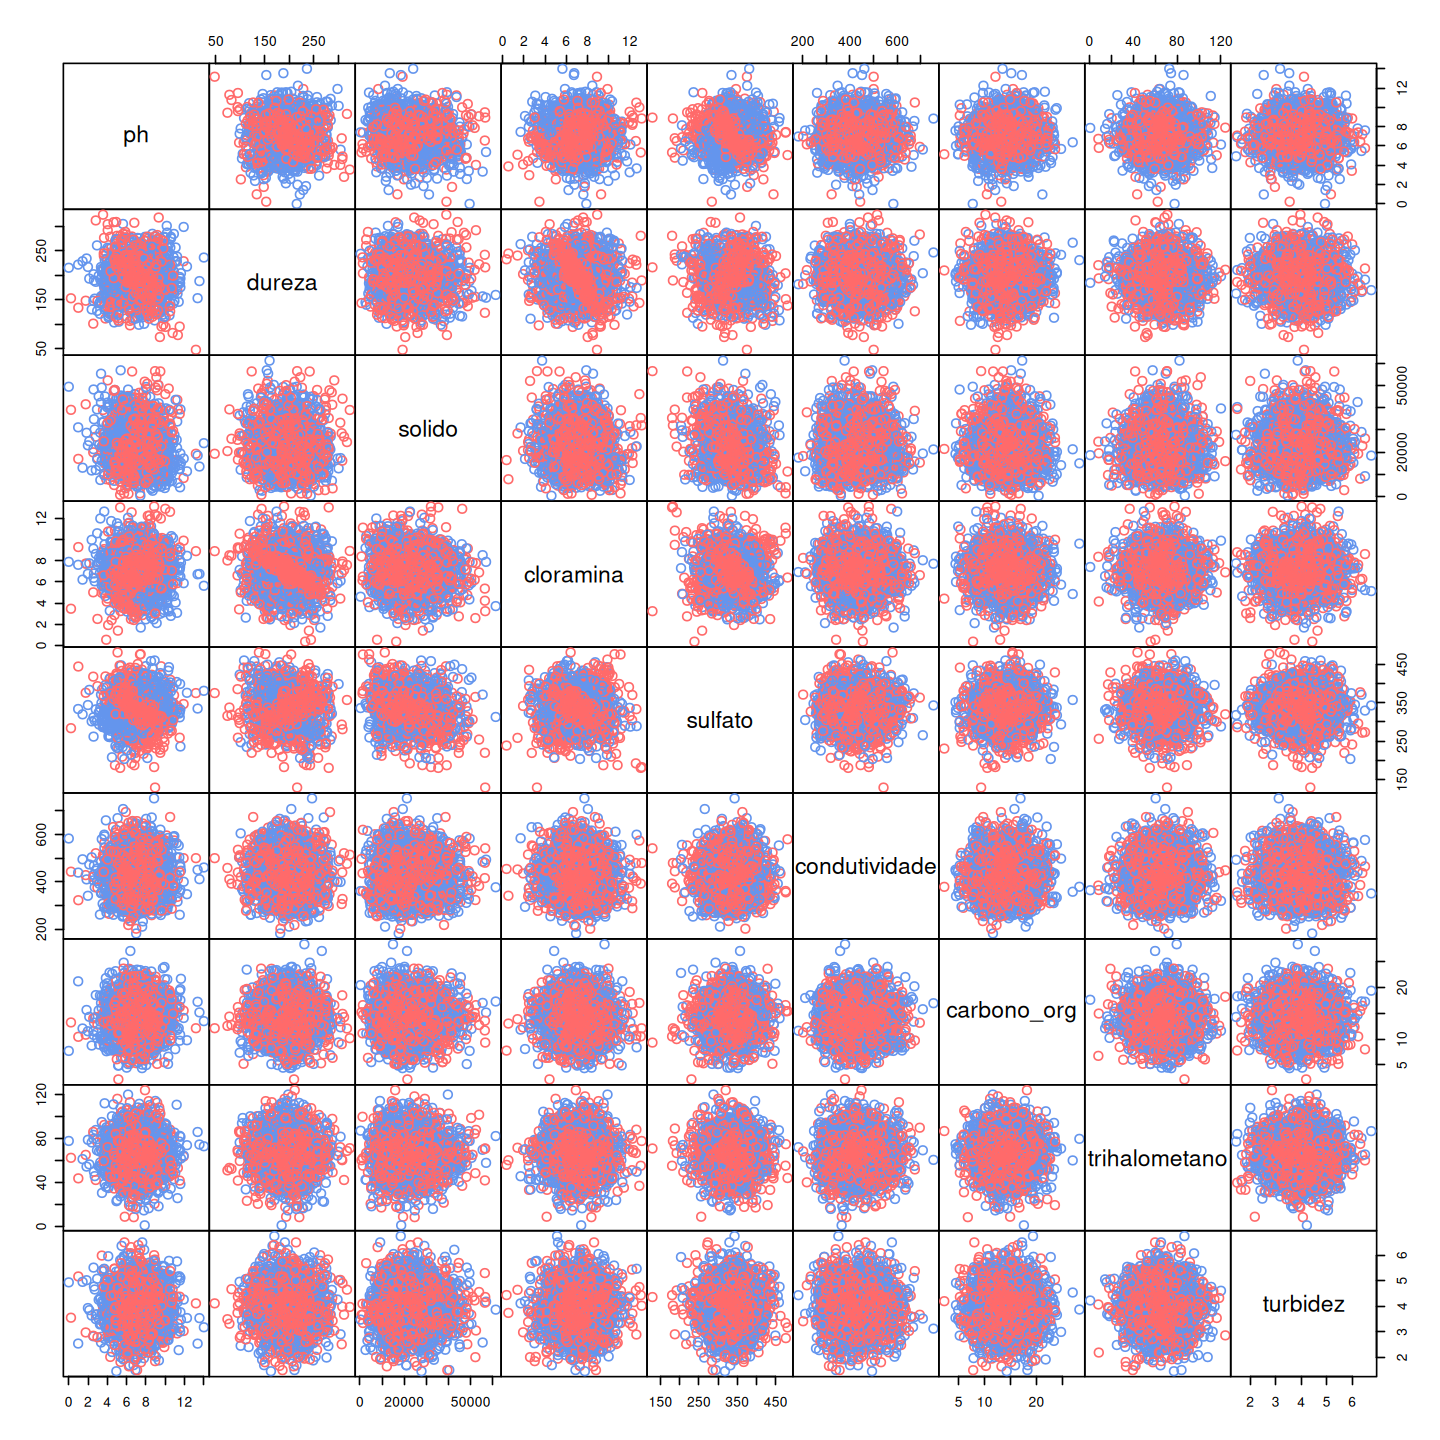

In [125]:
cores_graf <- ifelse(qa$potavel == 0, "cornflowerblue", "indianred1")
pairs(qa[,c(1:9)], col=cores_graf, cex=1.3, cex.labels=1.7, gap=0)

Verificando o comportamento conjunto das variáveis para tentar uma estratégia para substituir os NAs.

In [126]:
correlacao <- cor(qa[,1:9], use="pairwise.complete.obs")
correlacao

,ph,dureza,solido,cloramina,sulfato,condutividade,carbono_org,trihalometano,turbidez
ph,1.00000,0.08210,-0.08929,-0.03435,0.0182,0.01861,0.04350,0.00335,-0.03906
dureza,0.08210,1.00000,-0.04690,-0.03005,-0.1069,-0.02391,0.00361,-0.01301,-0.01445
solido,-0.08929,-0.04690,1.00000,-0.07015,-0.1718,0.01383,0.01024,-0.00914,0.01955
cloramina,-0.03435,-0.03005,-0.07015,1.00000,0.0272,-0.02049,-0.01265,0.01708,0.00236
sulfato,0.01820,-0.10692,-0.17180,0.02724,1.0000,-0.01612,0.03083,-0.03027,-0.01119
condutividade,0.01861,-0.02391,0.01383,-0.02049,-0.0161,1.00000,0.02097,0.00129,0.00580
carbono_org,0.04350,0.00361,0.01024,-0.01265,0.0308,0.02097,1.00000,-0.01327,-0.02731
trihalometano,0.00335,-0.01301,-0.00914,0.01708,-0.0303,0.00129,-0.01327,1.00000,-0.02214
turbidez,-0.03906,-0.01445,0.01955,0.00236,-0.0112,0.00580,-0.02731,-0.02214,1.00000


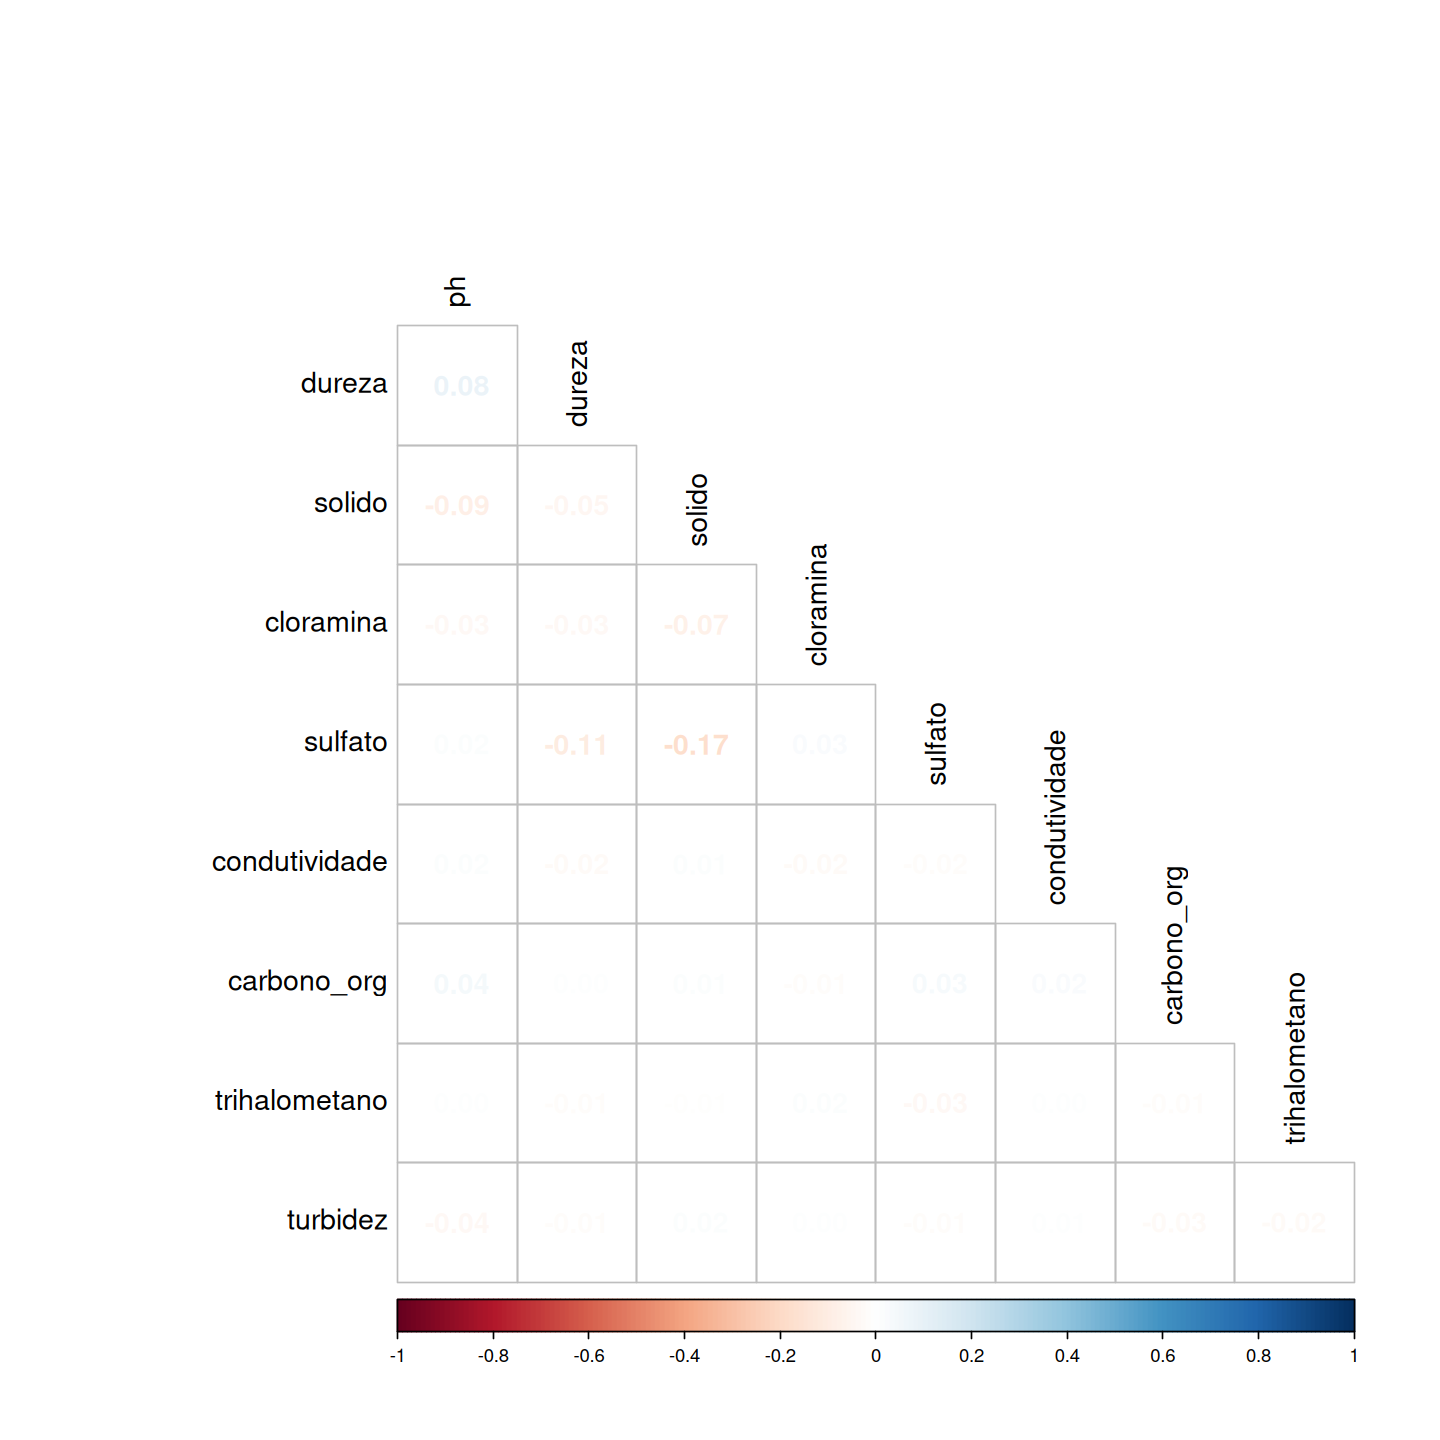

In [127]:
grafdim(12,12)
corrplot(correlacao, method='number', type='lower', diag=FALSE, 
         tl.cex=1.4, tl.col="black", cl.cex=0.9, number.cex=1.4)

Não há correlação entre as variáveis. Como os `NA`s são mais frequentes nos negativos (que são mais frequentes), vamos inicialmente simplesmente excluir as observações com algum dado perdido.

In [128]:
qan <- qa[!(is.na(qa$ph) | is.na(qa$sulfato) | is.na(qa$trihalometano)), ]

In [129]:
summary(qan)

       ph             dureza          solido        cloramina        sulfato   
 Min.   : 0.227   Min.   : 73.5   Min.   :  321   Min.   : 1.39   Min.   :129  
 1st Qu.: 6.090   1st Qu.:176.7   1st Qu.:15616   1st Qu.: 6.14   1st Qu.:308  
 Median : 7.027   Median :197.2   Median :20934   Median : 7.14   Median :332  
 Mean   : 7.086   Mean   :196.0   Mean   :21917   Mean   : 7.13   Mean   :333  
 3rd Qu.: 8.053   3rd Qu.:216.4   3rd Qu.:27183   3rd Qu.: 8.11   3rd Qu.:359  
 Max.   :14.000   Max.   :317.3   Max.   :56489   Max.   :13.13   Max.   :481  
 condutividade  carbono_org   trihalometano       turbidez       potavel     
 Min.   :202   Min.   : 2.2   Min.   :  8.58   Min.   :1.45   Min.   :0.000  
 1st Qu.:367   1st Qu.:12.1   1st Qu.: 55.95   1st Qu.:3.44   1st Qu.:0.000  
 Median :423   Median :14.3   Median : 66.54   Median :3.97   Median :0.000  
 Mean   :427   Mean   :14.4   Mean   : 66.40   Mean   :3.97   Mean   :0.403  
 3rd Qu.:482   3rd Qu.:16.7   3rd Qu.: 77.29   3rd

In [130]:
naph <- is.na(qan$ph)
nasu <- is.na(qan$sulfato)
natr <- is.na(qan$trihalometano)
nall <- naph | nasu | natr
npos <- sum(nall & qan$potavel == 1)
nneg <- sum(nall & qan$potavel == 0)
n    <- nrow(qan)

In [131]:
paste("Temos:")
paste("Casos positivos:",(round(npos / n * 100, 1)),"% (",npos,"em",n,")")
paste("Casos negativos:",(round(nneg / n * 100, 1)),"% (",nneg,"em",n,")")

[1] "Temos:"

[1] "Casos positivos: 0 % ( 0 em 2011 )"

[1] "Casos negativos: 0 % ( 0 em 2011 )"

Há dados perdidos (NAs) na variável resposta?

Quantos registros há comprometidos por NAs?

In [132]:
paste("Temos:")
paste("casos com NA: ",round(sum(nall)/n*100,2),"% (",sum(nall),"em",n,")")
paste("    casos positivos com NA:",round(sum(qan$potavel & nall) / n * 100, 2),"% (",sum(qan$potavel & nall),"em", n, ")")
paste("    casos negativos com NA:",round(sum(qan$potavel == 0 & nall) / n * 100, 2),"% (",sum(qan$potavel == 0 & nall),"em", n, ")")
rm(naph, nasu, natr, nall)

[1] "Temos:"

[1] "casos com NA:  0 % ( 0 em 2011 )"

[1] "    casos positivos com NA: 0 % ( 0 em 2011 )"

[1] "    casos negativos com NA: 0 % ( 0 em 2011 )"

In [133]:
str(qan)

'data.frame':	2011 obs. of  10 variables:
 $ ph           : num  8.32 9.09 5.58 10.22 8.64 ...
 $ dureza       : num  214 181 188 248 203 ...
 $ solido       : num  22018 17979 28749 28750 13672 ...
 $ cloramina    : num  8.06 6.55 7.54 7.51 4.56 ...
 $ sulfato      : num  357 310 327 394 303 ...
 $ condutividade: num  363 398 280 284 475 ...
 $ carbono_org  : num  18.4 11.6 8.4 13.8 12.4 ...
 $ trihalometano: num  100.3 32 54.9 84.6 62.8 ...
 $ turbidez     : num  4.63 4.08 2.56 2.67 4.4 ...
 $ potavel      : int  0 0 0 0 0 0 0 0 0 0 ...


### Conjuntos de **treino**, **validacao** e **teste**

Vamos separar os dados de teste e validação dos dados de treinamento

A questão é que devemos obter (e retirar) dos dados originais cada grupo (teste, validação) deixando apenas os dados de treinamento.

Vamos examinar a proporção de positivos na população:

In [134]:
round(sum(qan$potavel) / nrow(qan) * 100, 4)

[1] 40.3

In [135]:
npos <- sum(qan$potavel == 1)
nneg <- sum(qan$potavel == 0)
n    <- nrow(qan)
paste("Temos:")
paste("Casos positivos:",(round(npos / n * 100, 1)),"% (",npos,"em",n,")")
paste("Casos negativos:",(round(nneg / n * 100, 1)),"% (",nneg,"em",n,")")

[1] "Temos:"

[1] "Casos positivos: 40.3 % ( 811 em 2011 )"

[1] "Casos negativos: 59.7 % ( 1200 em 2011 )"

Feita a subamostragem dos negativos, vamos separar os conjuntos em _treino_, _validação_ e _teste_.

In [136]:
# reservando 20% dos dados originais para teste
taxa_teste  <- 0.15
# reservando a mesma quantidade de teste para validação
taxa_valid  <- taxa_teste       
# o que sobrar é para o treinamento:
taxa_treino <- 1.0 - taxa_teste - taxa_valid

In [137]:
(n_teste  <- trunc(taxa_teste * nrow(qan)))
(n_valid  <- trunc(taxa_valid * nrow(qan)))

[1] 301

[1] 301

In [138]:
# reajustando a semente aleatória
set.seed(997)

In [139]:
# como vamos _retirar_ validação e teste, o que _sobrar_ é o treino
# então, inicialmente, o treino é todo mundo.
treino  <- qan

In [140]:
# amostrando n_teste valores dentre 1 até quantidade de 
# linhas de treino para o conjunto de TESTE
amostra <- sample(1:nrow(treino), n_teste, replace=FALSE)
teste   <- treino[amostra,]   # "teste" recebe as linhas amostradas
treino  <- treino[-amostra,]  # retirando de "treino" os elementos do teste

In [141]:
# amostrando n_valid valores dentre 1 até quantidade de 
# linhas (restantes) de treino para o conjunto de VALIDAÇÃO
amostra <- sample(1:nrow(treino), n_valid, replace=FALSE)
valid   <- treino[amostra,]
treino  <- treino[-amostra,]     # retirando de "treino" os elementos da validação

In [142]:
nrow(teste)
nrow(valid)
nrow(treino)

[1] 301

[1] 301

[1] 1409

Vamos então checar os conjuntos de dados:

In [143]:
print(merge(treino, valid,  all=FALSE))

 [1] ph            dureza        solido        cloramina     sulfato      
 [6] condutividade carbono_org   trihalometano turbidez      potavel      
<0 rows> (or 0-length row.names)


Ok, há zero registros em comum entre treino e validação.

In [144]:
print(merge(treino, teste,  all=FALSE))

 [1] ph            dureza        solido        cloramina     sulfato      
 [6] condutividade carbono_org   trihalometano turbidez      potavel      
<0 rows> (or 0-length row.names)


Ok, há zero registros em comum entre treino e teste.

In [145]:
print(merge(valid, teste,  all=FALSE))

 [1] ph            dureza        solido        cloramina     sulfato      
 [6] condutividade carbono_org   trihalometano turbidez      potavel      
<0 rows> (or 0-length row.names)


Ok, há zero registros em comum entre treino e teste, podemos começar o aprendizado.

### Avaliação dos dados:

In [146]:
summary(treino)

       ph             dureza          solido        cloramina        sulfato   
 Min.   : 0.227   Min.   : 73.5   Min.   : 1199   Min.   : 1.39   Min.   :182  
 1st Qu.: 6.128   1st Qu.:177.2   1st Qu.:15662   1st Qu.: 6.15   1st Qu.:308  
 Median : 7.064   Median :197.6   Median :20770   Median : 7.13   Median :333  
 Mean   : 7.109   Mean   :196.1   Mean   :21894   Mean   : 7.13   Mean   :333  
 3rd Qu.: 8.121   3rd Qu.:216.1   3rd Qu.:27200   3rd Qu.: 8.12   3rd Qu.:359  
 Max.   :14.000   Max.   :317.3   Max.   :56351   Max.   :13.13   Max.   :481  
 condutividade  carbono_org   trihalometano      turbidez       potavel     
 Min.   :202   Min.   : 2.2   Min.   : 14.3   Min.   :1.49   Min.   :0.000  
 1st Qu.:368   1st Qu.:12.0   1st Qu.: 54.9   1st Qu.:3.44   1st Qu.:0.000  
 Median :423   Median :14.2   Median : 65.9   Median :3.97   Median :0.000  
 Mean   :427   Mean   :14.3   Mean   : 65.7   Mean   :3.97   Mean   :0.402  
 3rd Qu.:483   3rd Qu.:16.6   3rd Qu.: 76.5   3rd Qu.:4

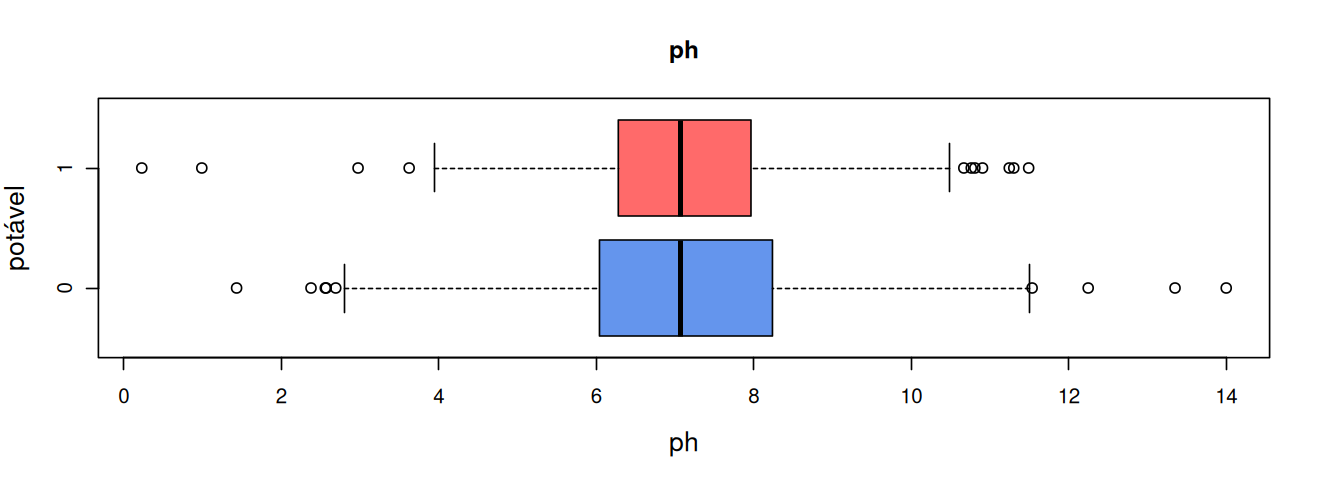

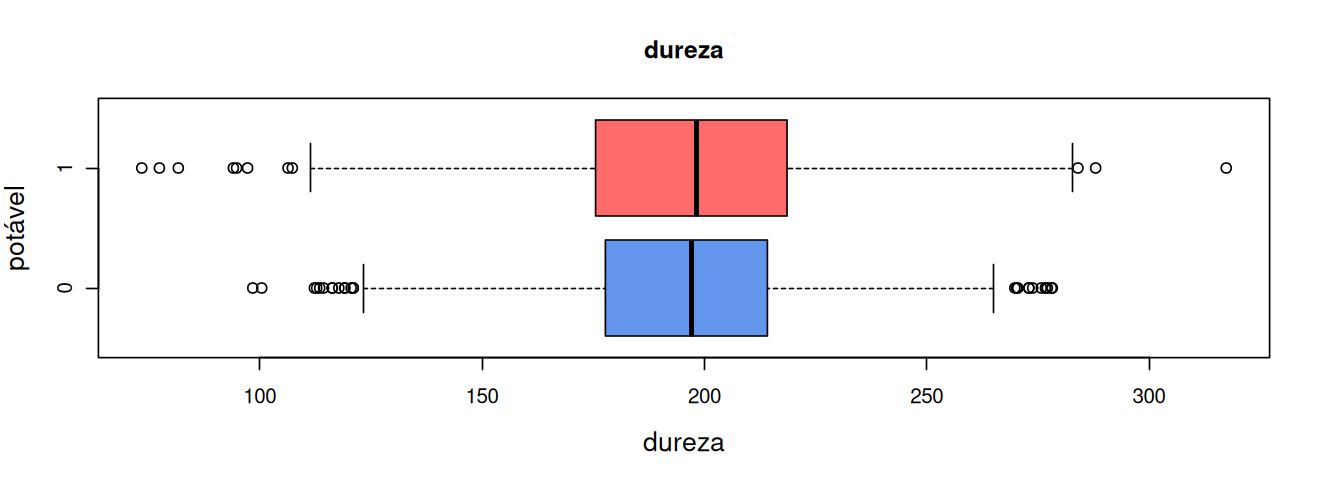

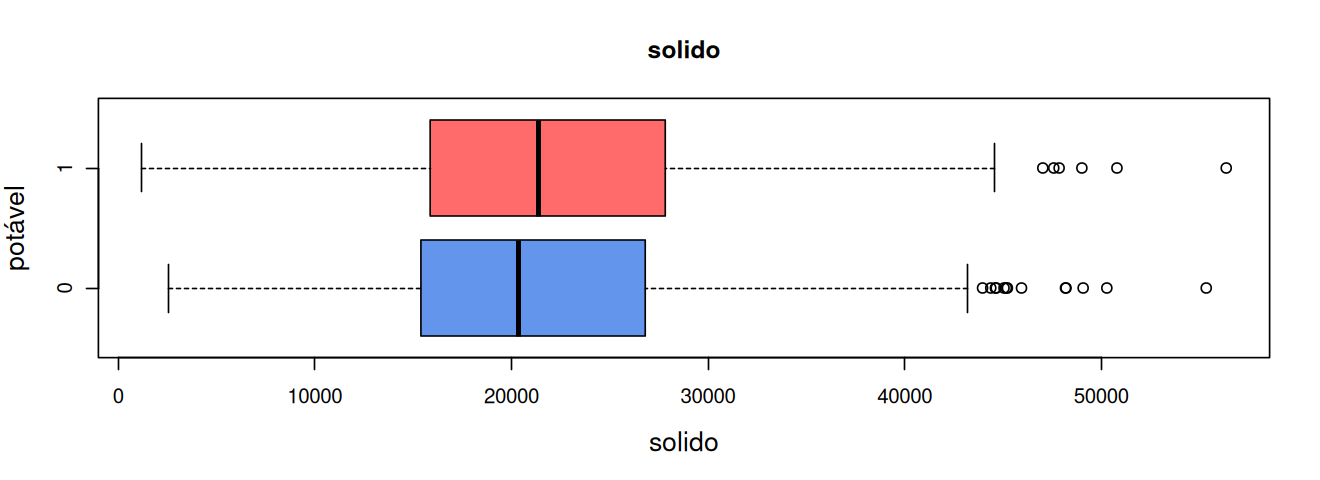

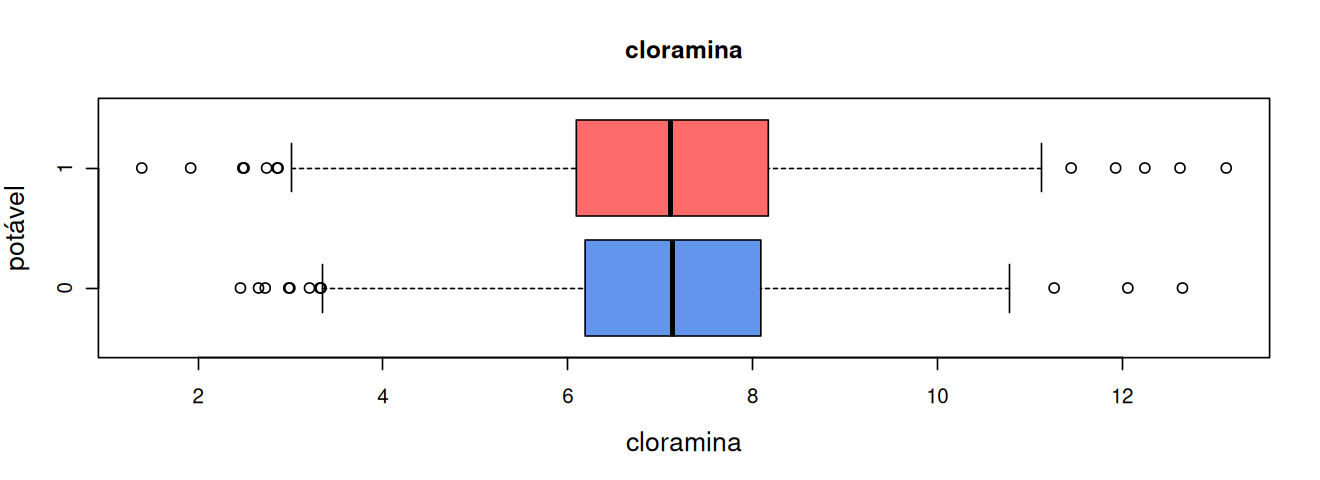

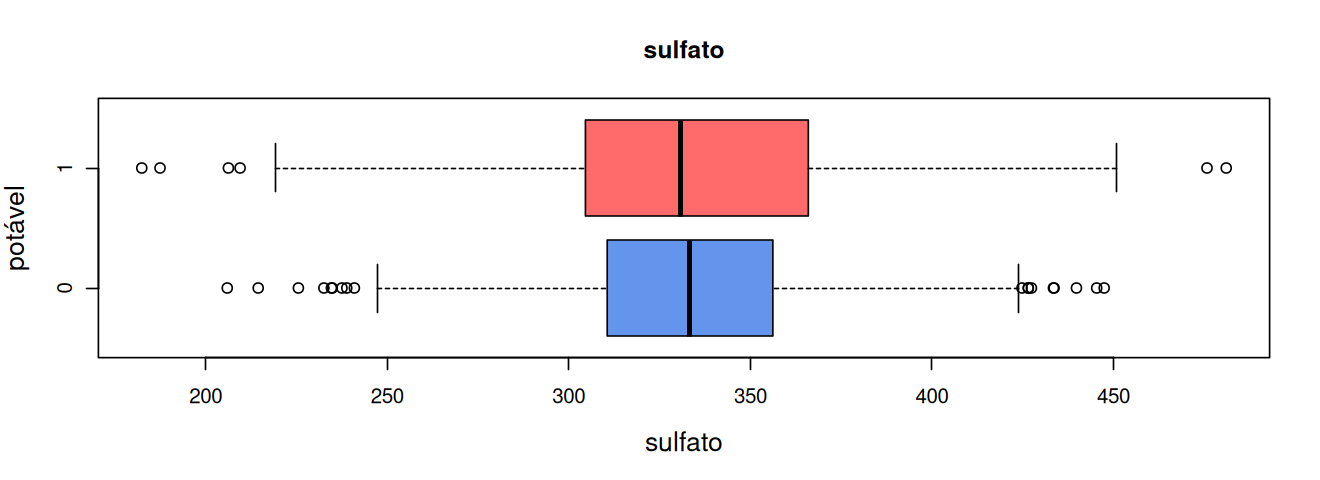

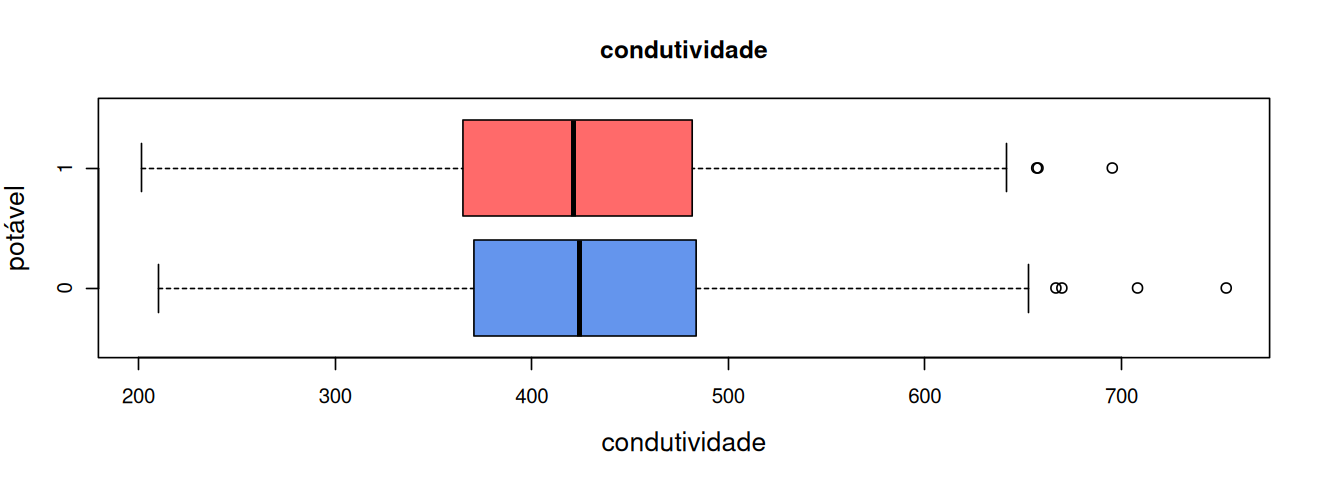

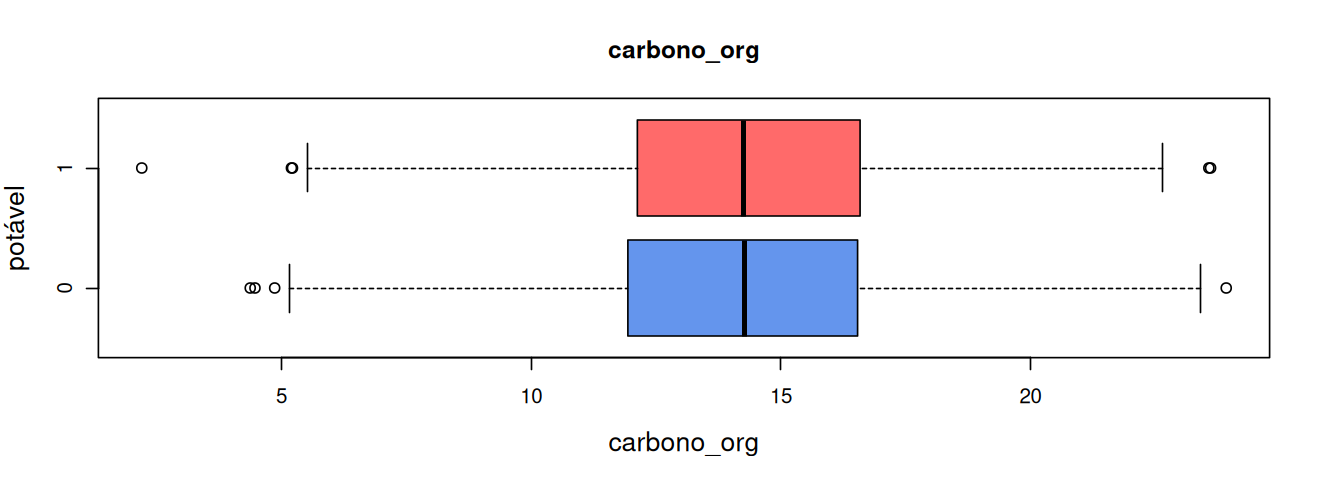

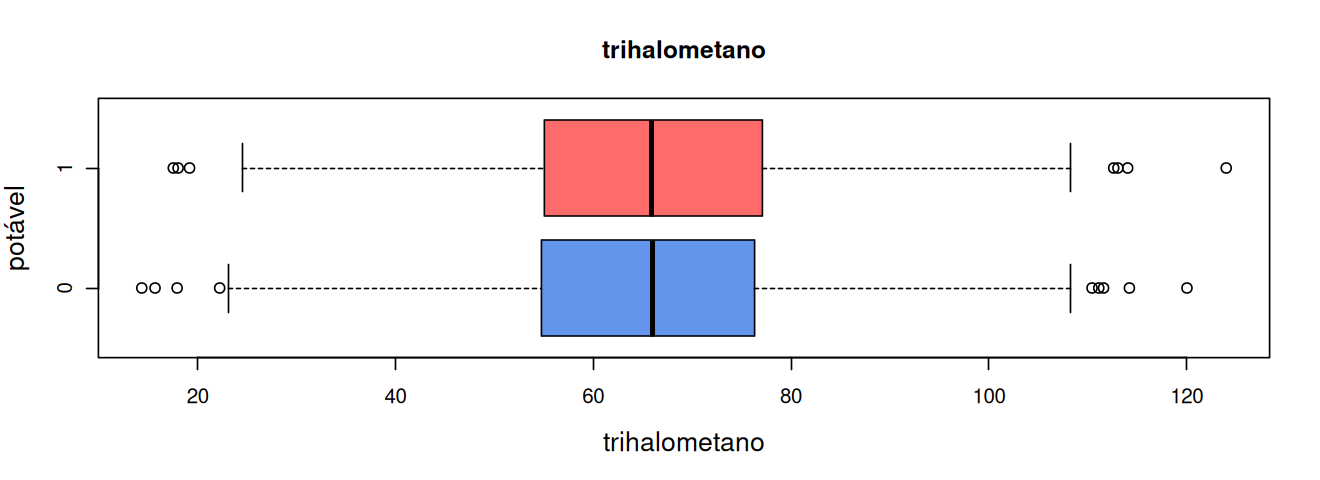

In [147]:
grafdim(11,4)
for (i in 1:8) {
    boxplot(treino[,i] ~ treino$potavel, main=names(treino)[i], 
            horizontal=TRUE, col=cores, cex.lab=1.3, 
            xlab=names(treino)[i], ylab="potável")
}

In [148]:
nomes <- names(qan)
nomes <- nomes[-10]
nomes

[1] "ph"            "dureza"        "solido"        "cloramina"    
[5] "sulfato"       "condutividade" "carbono_org"   "trihalometano"
[9] "turbidez"

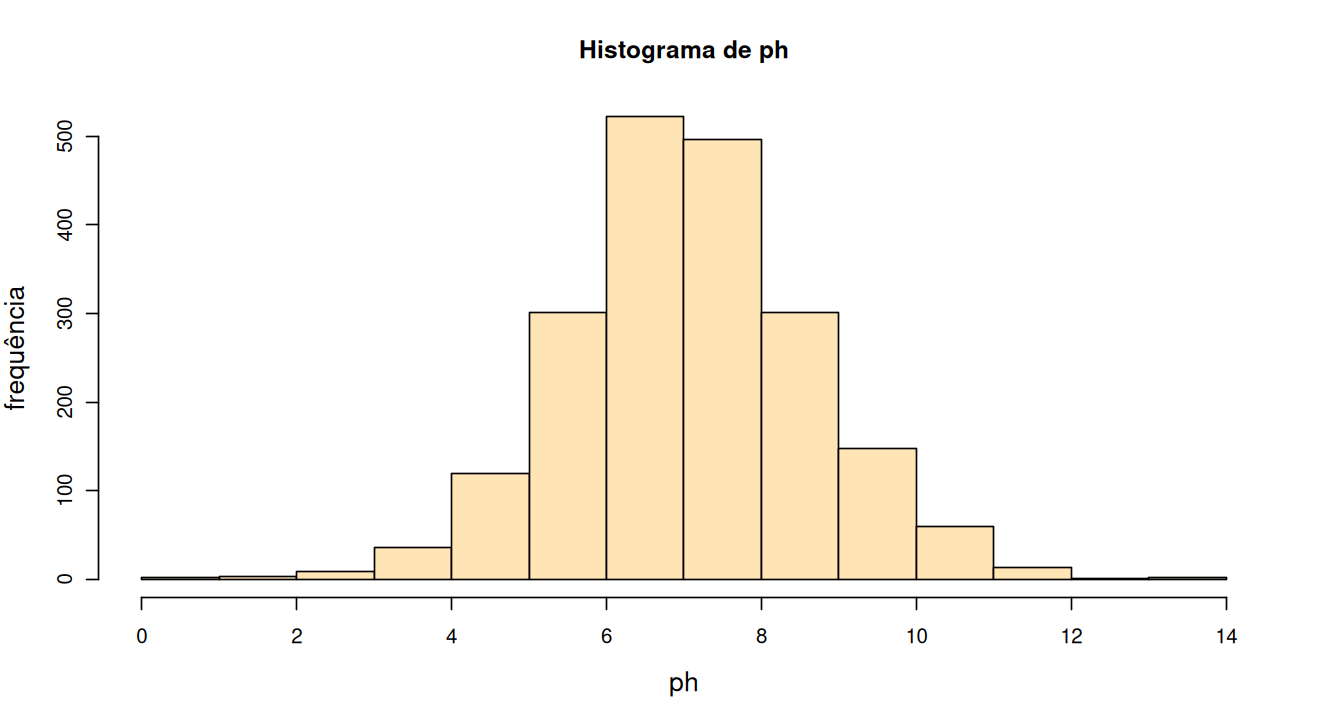

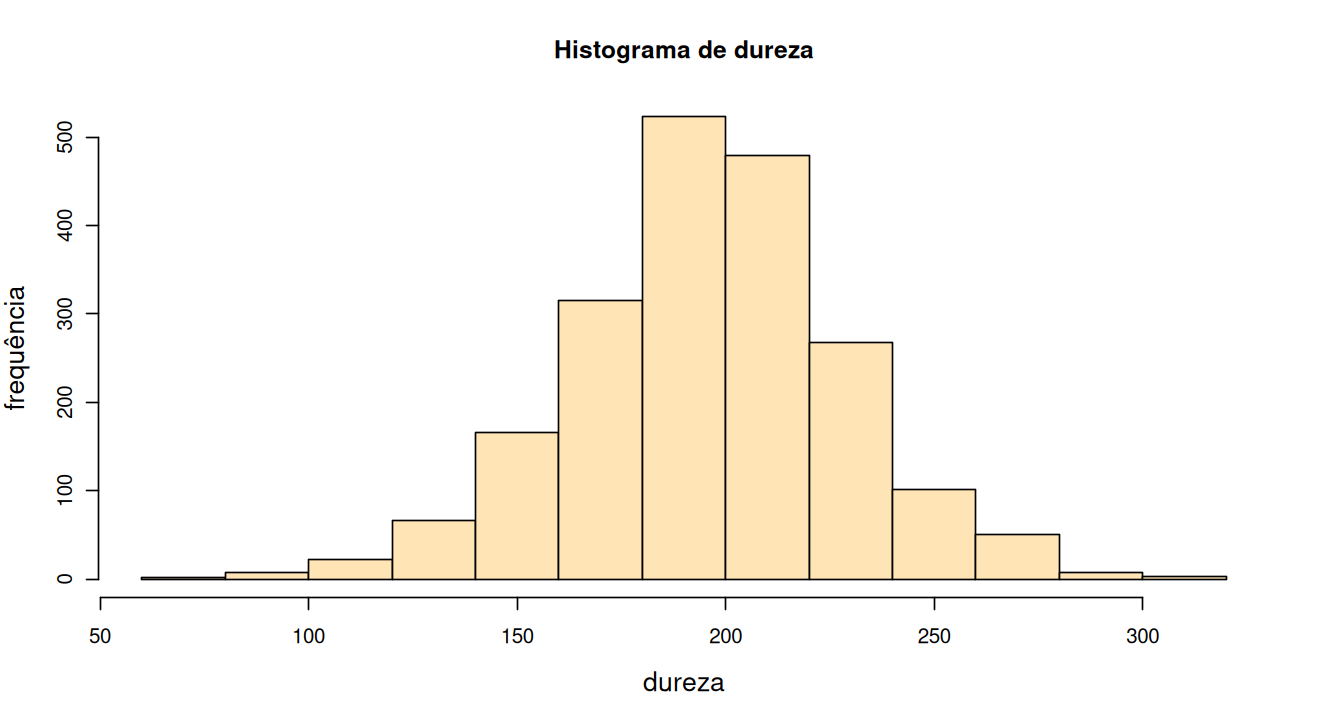

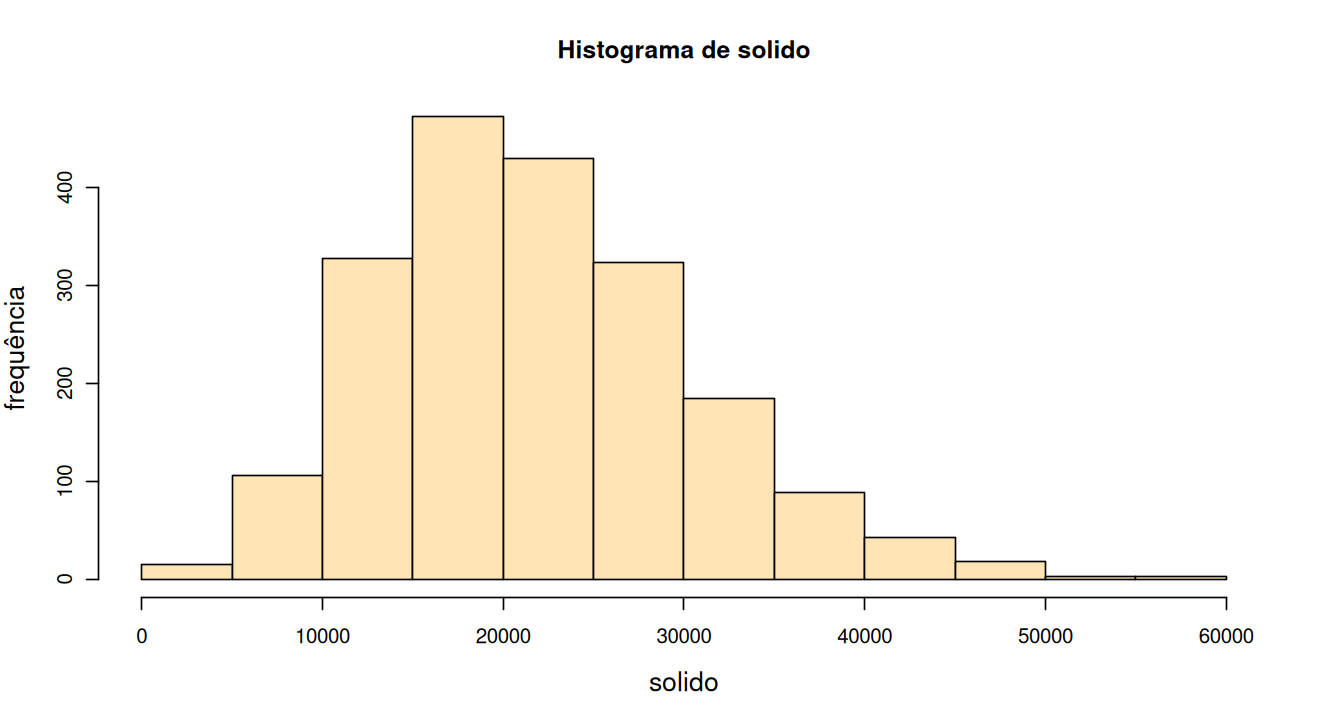

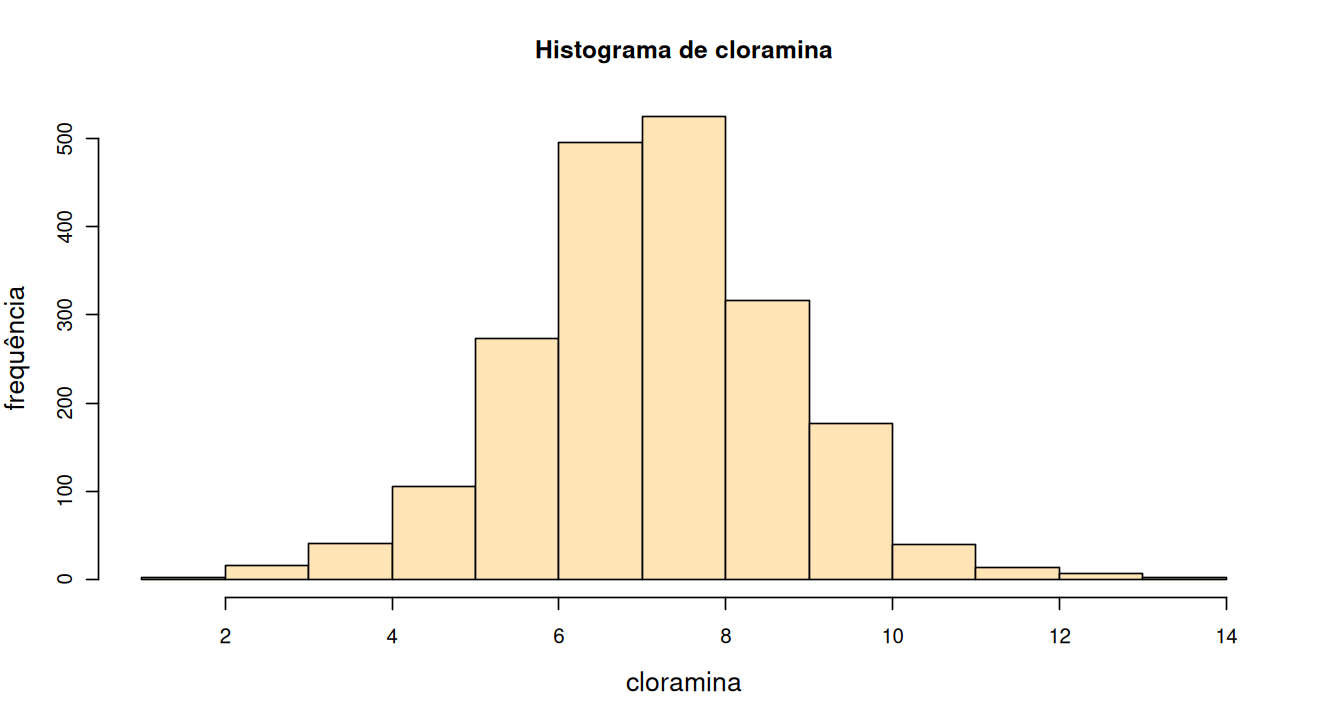

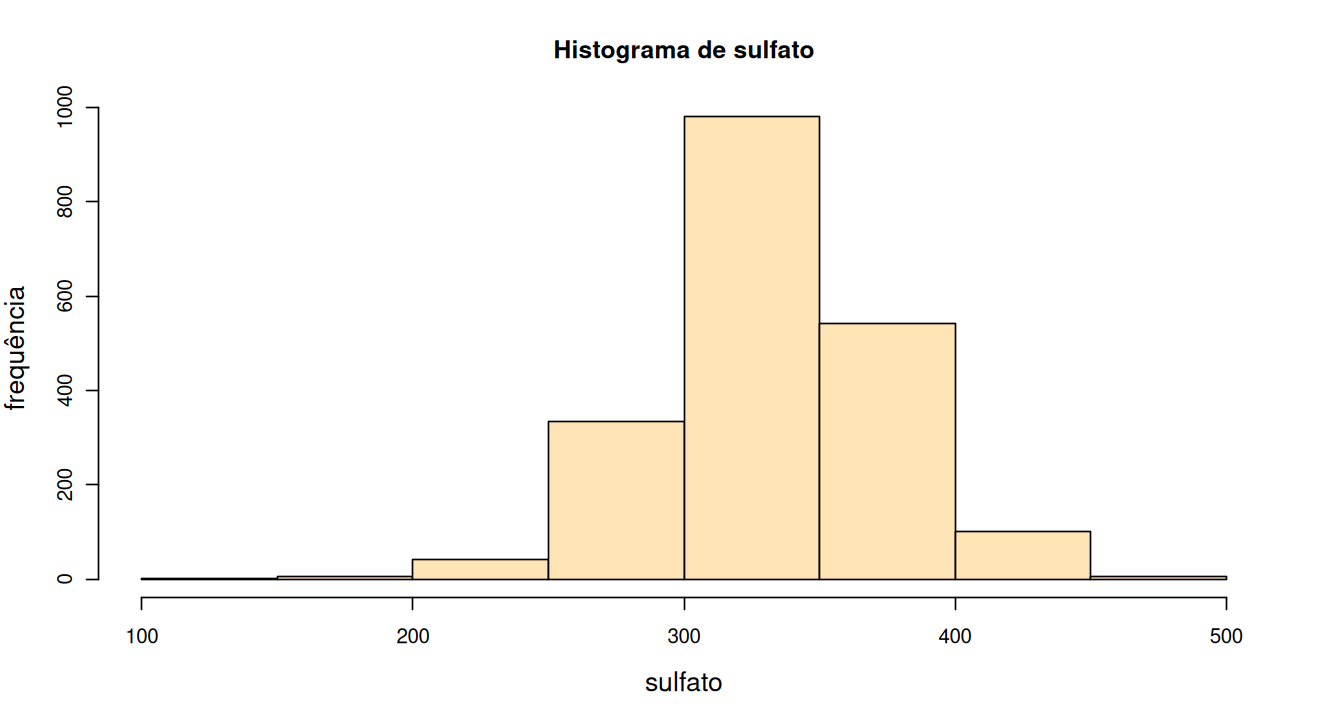

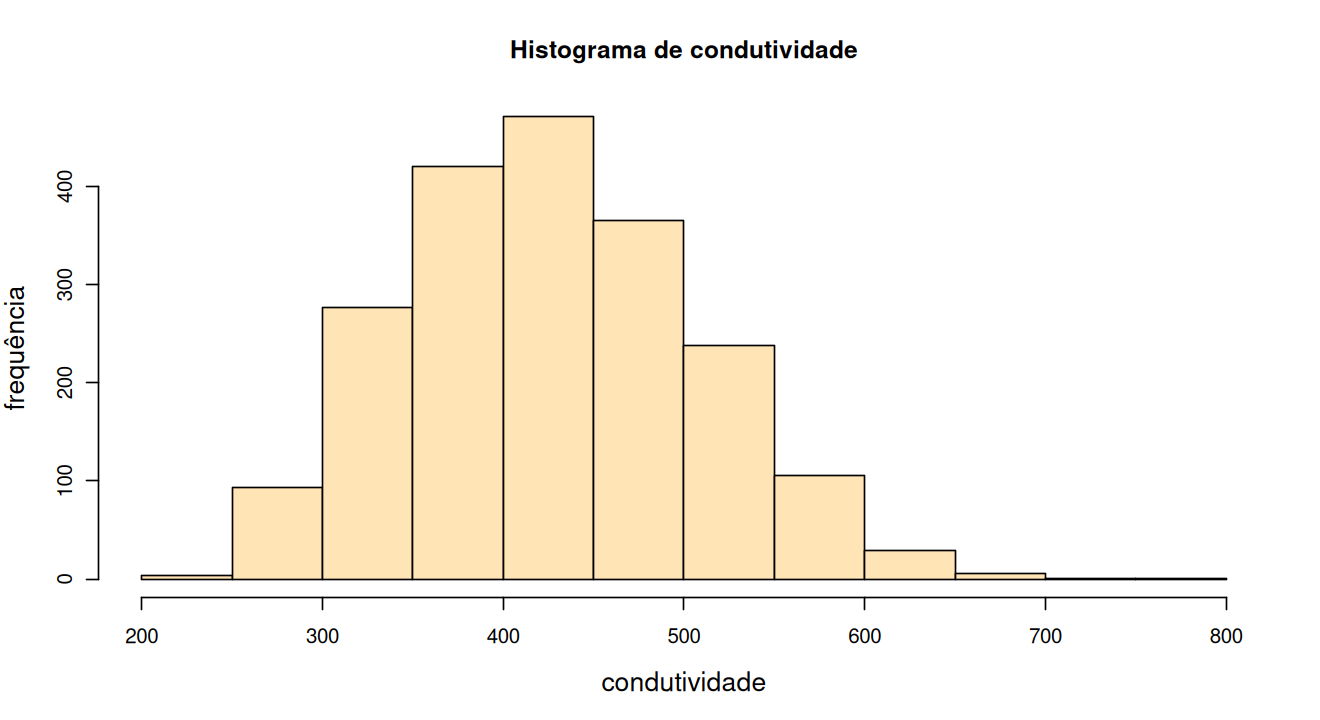

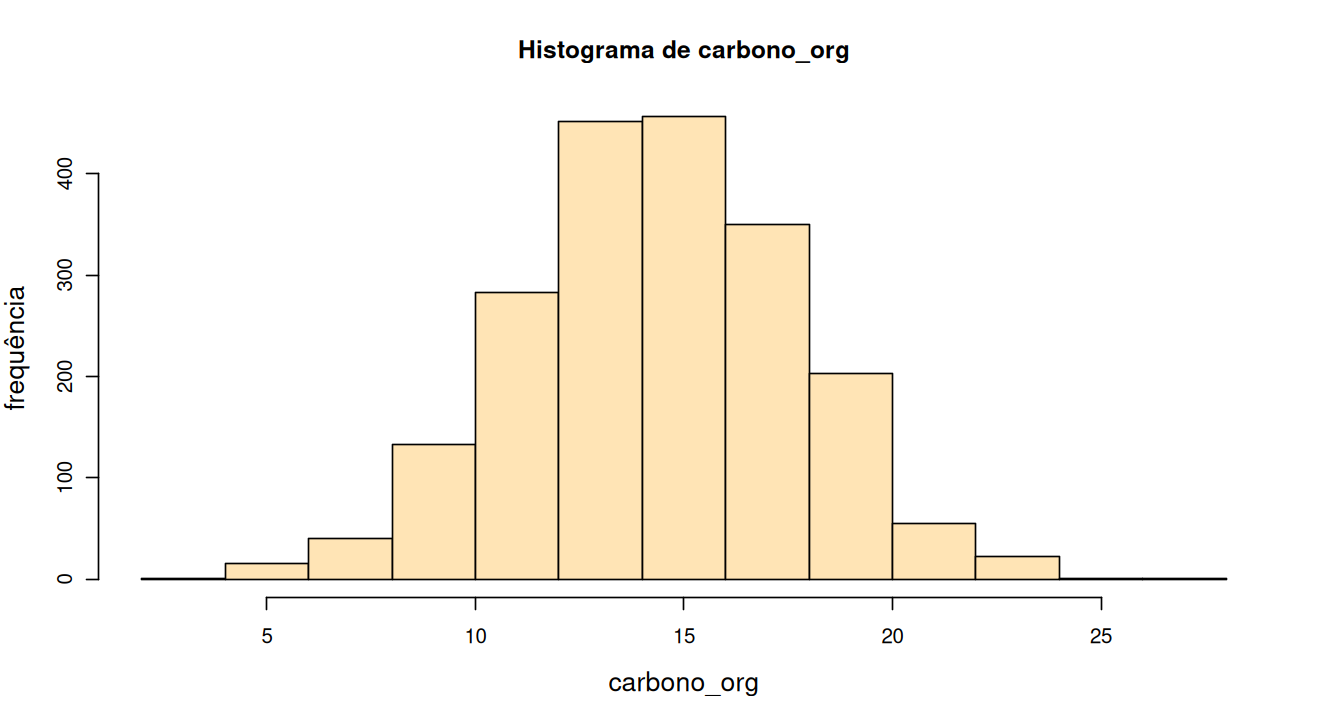

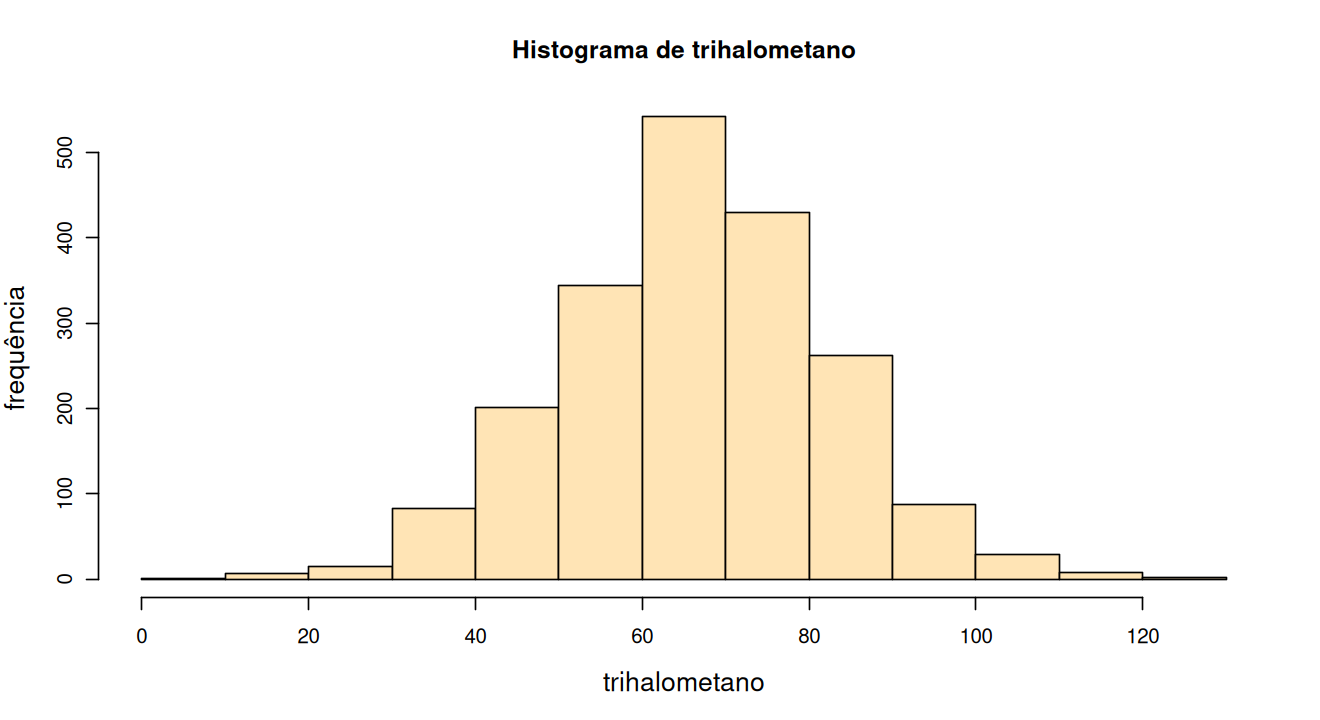

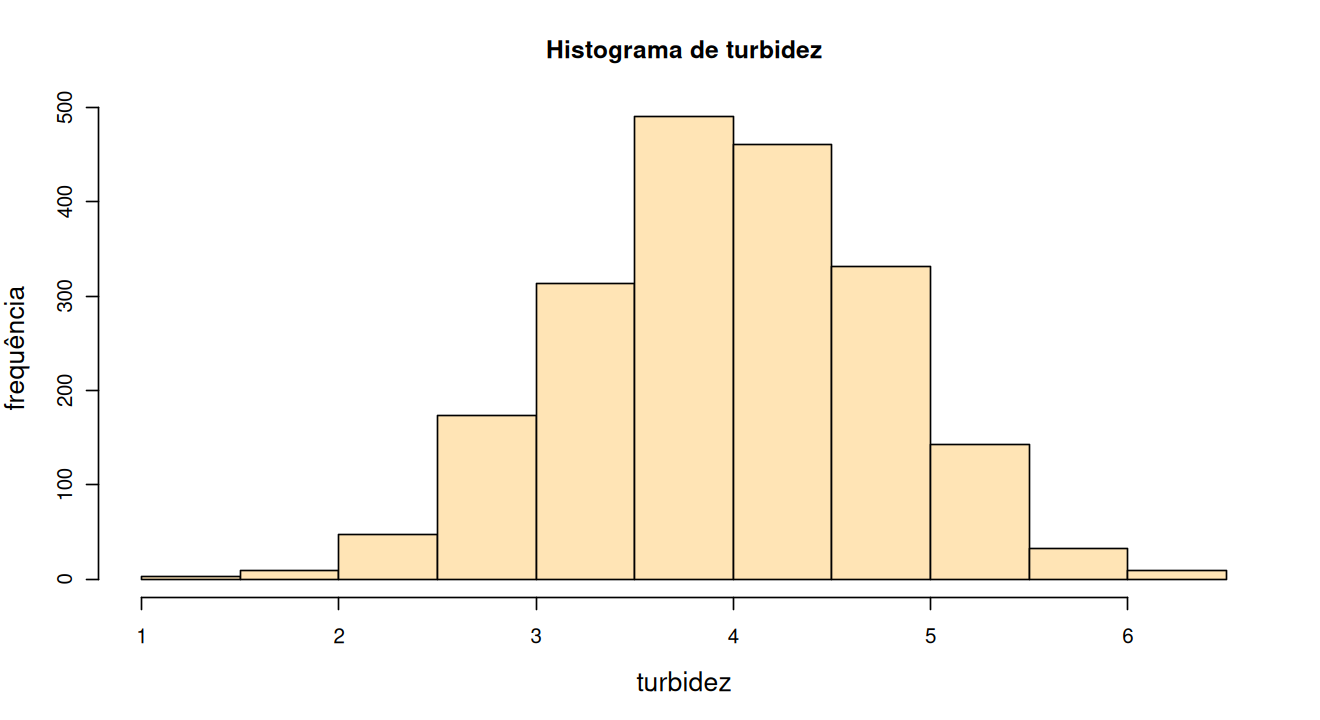

In [149]:
grafdim(11,6)
for (i in nomes) {
    hist(qan[,i], col="moccasin", main=paste("Histograma de",i), 
         ylab="frequência", xlab=i, cex.lab=1.3)
}

## Modelo Padrão-Base (_Baseline_ )

Vamos construir um _padrão-base_ (`baseline`) para termos um critério para saber como os modelos estão se comportando.

In [150]:
library(rpart)  # árvores de decisão
library(repr)   # representações (ajuste gráfico do jupyter)
library(caret)  # matriz de confusão
library(rpart.plot)
library(RColorBrewer)

In [151]:
grafdim <- function(x=11, y=9) { options(repr.plot.width=x, repr.plot.height=y) }
grafdim()

In [152]:
str(treino)

'data.frame':	1409 obs. of  10 variables:
 $ ph           : num  8.32 5.58 10.22 11.18 7.12 ...
 $ dureza       : num  214 188 248 227 157 ...
 $ solido       : num  22018 28749 28750 25485 18731 ...
 $ cloramina    : num  8.06 7.54 7.51 9.08 3.61 ...
 $ sulfato      : num  357 327 394 404 282 ...
 $ condutividade: num  363 280 284 564 348 ...
 $ carbono_org  : num  18.4 8.4 13.8 17.9 15.9 ...
 $ trihalometano: num  100.3 54.9 84.6 72 79.5 ...
 $ turbidez     : num  4.63 2.56 2.67 4.37 3.45 ...
 $ potavel      : int  0 0 0 0 0 0 0 0 0 0 ...


In [153]:
mod_bas <- rpart(potavel ~ . , data=treino, 
                     method="class",
                     minsplit=20, minbucket=7, maxdepth=30)

In [154]:
printcp(mod_bas)


Classification tree:
rpart(formula = potavel ~ ., data = treino, method = "class", 
    minsplit = 20, minbucket = 7, maxdepth = 30)

Variables actually used in tree construction:
[1] cloramina dureza    ph        solido    sulfato  

Root node error: 567/1409 = 0.4

n= 1409 

    CP nsplit rel error xerror xstd
1 0.04      0       1.0    1.0 0.03
2 0.04      1       1.0    1.0 0.03
3 0.02      3       0.9    0.9 0.03
4 0.01     11       0.7    0.9 0.03
5 0.01     13       0.7    0.9 0.03


In [155]:
print(mod_bas$variable.importance)

           ph        solido        dureza       sulfato     cloramina 
       49.744        23.991        23.558        23.549         6.820 
     turbidez condutividade trihalometano   carbono_org 
        1.984         1.945         1.843         0.448 


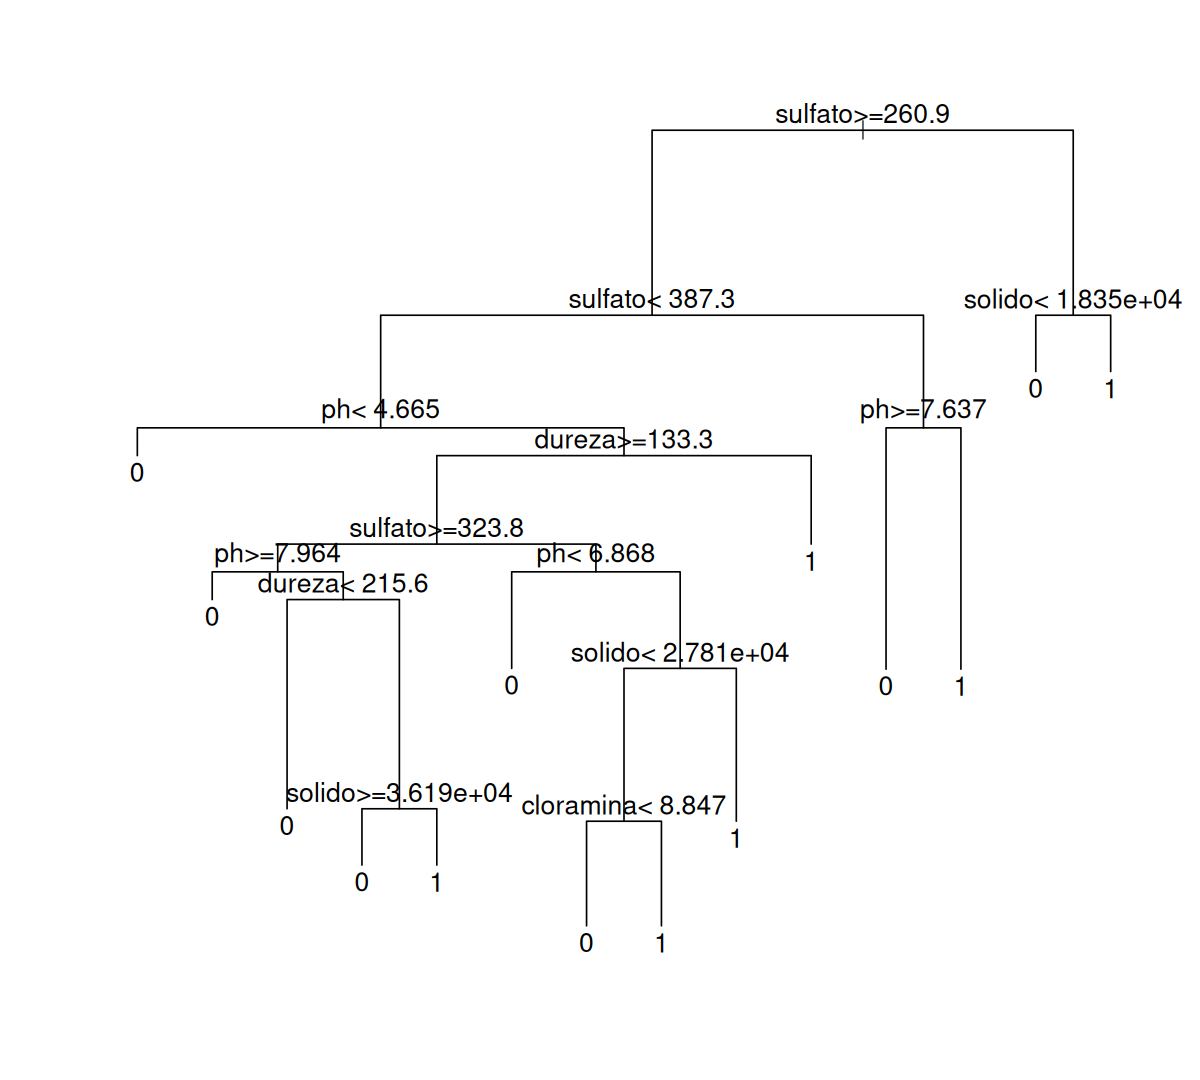

In [74]:
grafdim(10,9)
plot(mod_bas)
text(mod_bas, cex=1.3, xpd=TRUE)

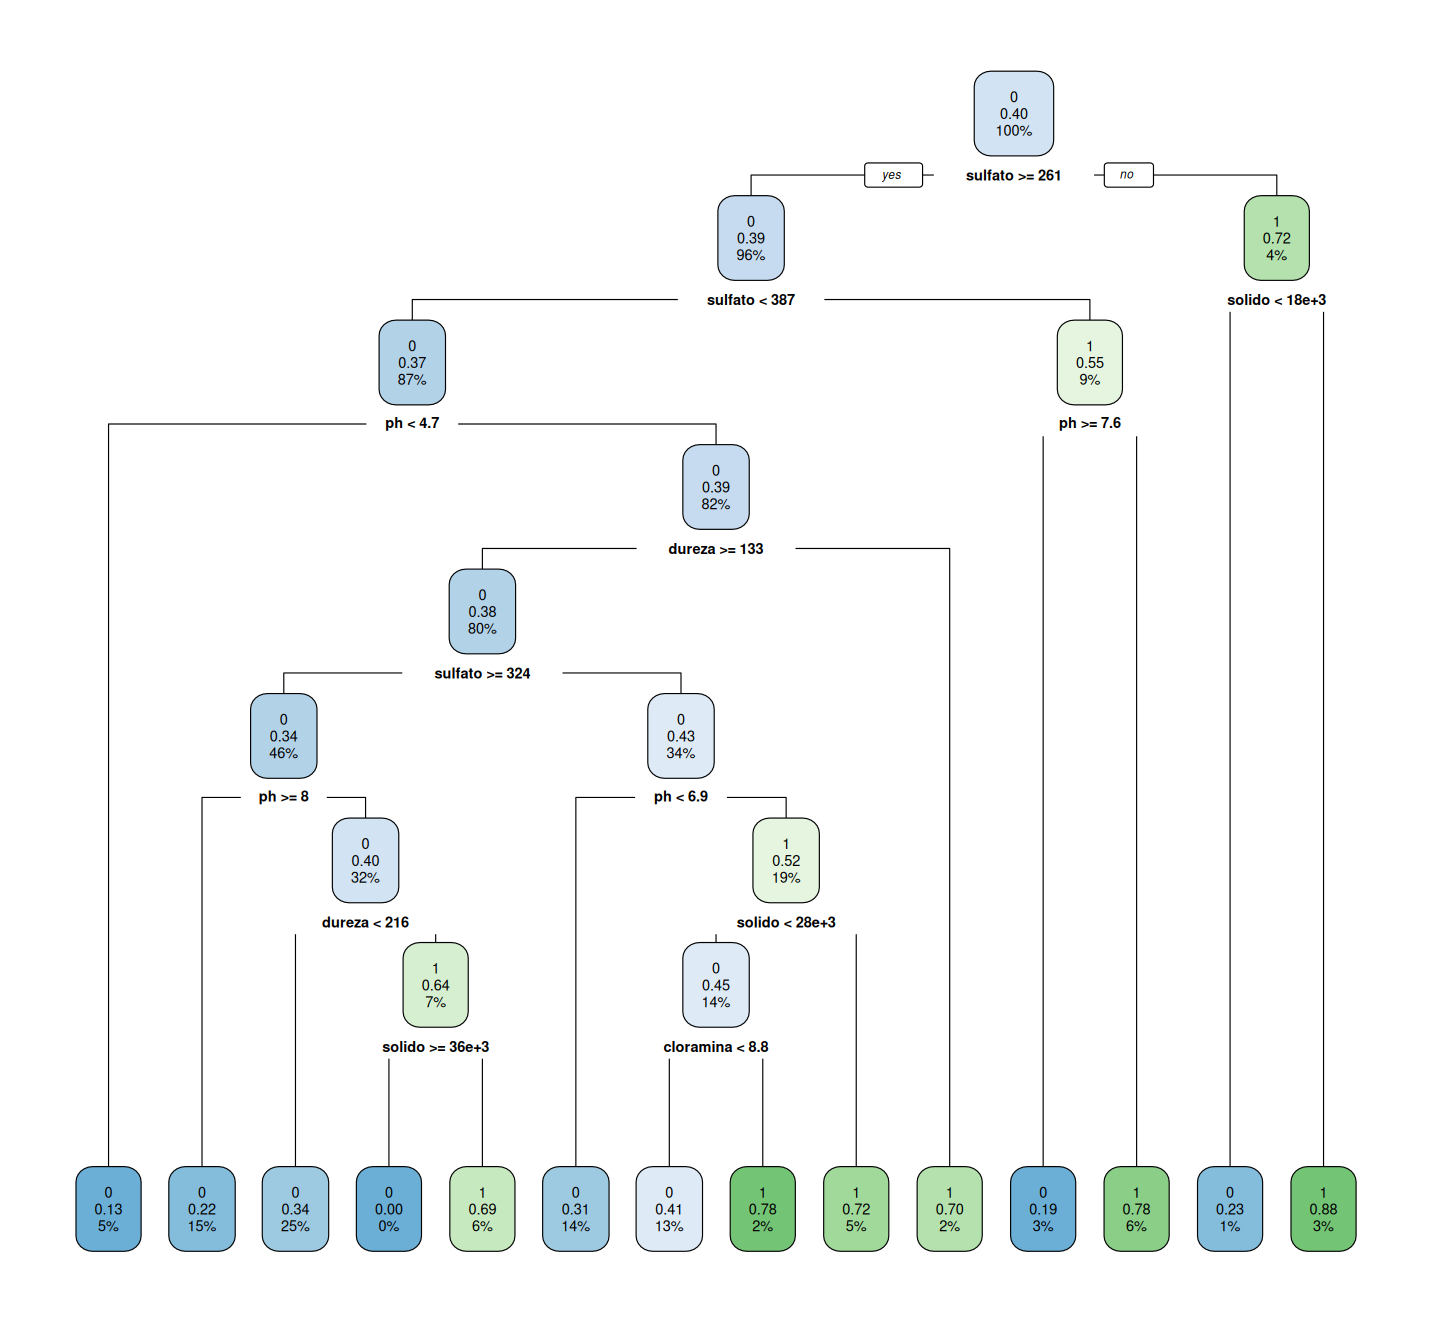

In [75]:
grafdim(12,11)
rpart.plot(mod_bas)

In [76]:
predito <- predict(mod_bas, treino, type="class")

In [77]:
str(predito)
str(treino$potavel)

 Factor w/ 2 levels "0","1": 1 1 1 1 1 1 1 1 1 1 ...
 - attr(*, "names")= chr [1:1409] "4" "6" "7" "10" ...
 int [1:1409] 0 0 0 0 0 0 0 0 0 0 ...


In [78]:
print(head(predito,25))

 4  6  7 10 13 16 18 20 25 27 33 34 37 40 44 47 50 52 53 54 55 57 58 62 67 
 0  0  0  0  0  0  0  0  0  0  1  1  0  0  0  0  0  0  0  0  0  0  0  0  1 
Levels: 0 1


In [79]:
(mat_confus <- confusionMatrix(data=predito, reference=factor(treino$potavel), positive="1"))

Confusion Matrix and Statistics

          Reference
Prediction   0   1
         0 759 322
         1  83 245
                                        
               Accuracy : 0.713         
                 95% CI : (0.688, 0.736)
    No Information Rate : 0.598         
    P-Value [Acc > NIR] : <2e-16        
                                        
                  Kappa : 0.358         
                                        
 Mcnemar's Test P-Value : <2e-16        
                                        
            Sensitivity : 0.432         
            Specificity : 0.901         
         Pos Pred Value : 0.747         
         Neg Pred Value : 0.702         
             Prevalence : 0.402         
         Detection Rate : 0.174         
   Detection Prevalence : 0.233         
      Balanced Accuracy : 0.667         
                                        
       'Positive' Class : 1             
                                        

In [80]:
(mod_bas_treino_acbal <- mat_confus$byClass["Balanced Accuracy"])

Balanced Accuracy 
            0.667

In [81]:
tabela <- as.data.frame(mat_confus$table)
tabela$Reference <- factor(tabela$Reference, levels=rev(levels(tabela$Reference)))
tabela

Prediction,Reference,Freq
<fct>,<fct>,<int>
0,0,759
1,0,83
0,1,322
1,1,245


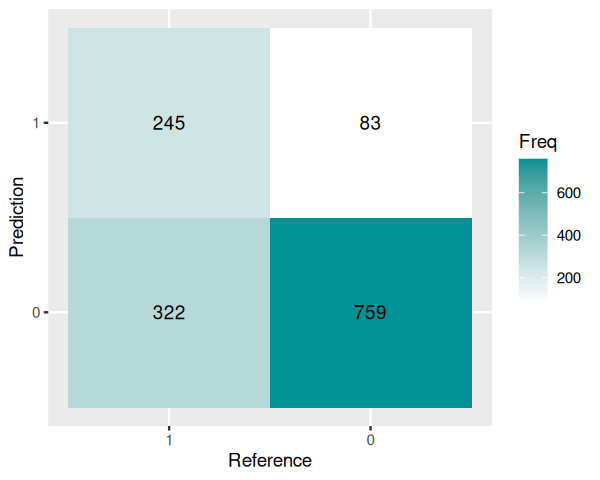

In [82]:
grafdim(5,4)
ggplot(tabela, aes(Reference, Prediction, fill=Freq)) +
        geom_tile() + geom_text(aes(label=Freq)) +
        scale_fill_gradient(low="white", high="#009194") +
        labs(x="Reference",y="Prediction" )

In [83]:
predito <- predict(mod_bas, new=valid, type="class")

In [84]:
(mat_confus <- confusionMatrix(data=predito, reference=factor(valid$potavel), positive="1"))

Confusion Matrix and Statistics

          Reference
Prediction   0   1
         0 160  74
         1  26  41
                                        
               Accuracy : 0.668         
                 95% CI : (0.611, 0.721)
    No Information Rate : 0.618         
    P-Value [Acc > NIR] : 0.0418        
                                        
                  Kappa : 0.235         
                                        
 Mcnemar's Test P-Value : 2.6e-06       
                                        
            Sensitivity : 0.357         
            Specificity : 0.860         
         Pos Pred Value : 0.612         
         Neg Pred Value : 0.684         
             Prevalence : 0.382         
         Detection Rate : 0.136         
   Detection Prevalence : 0.223         
      Balanced Accuracy : 0.608         
                                        
       'Positive' Class : 1             
                                        

In [85]:
(mod_bas_valid_acbal <- mat_confus$byClass["Balanced Accuracy"])

Balanced Accuracy 
            0.608

## Modelo Árvore Podada

Árvores de decisão completas tendem a sofrer de _overfiting_ pois se esforçam em ser o mais adequadas possível aos dados de treinamento, perdendo generalização. Uma solução é a poda ("pruning") da árvore, garantindo que não fique muito complexa nem muito específica, ao utilizar só as principais decisões.

In [157]:
mod_arv <- rpart(potavel ~ . , data=treino,  method="class")

In [158]:
printcp(mod_arv)


Classification tree:
rpart(formula = potavel ~ ., data = treino, method = "class")

Variables actually used in tree construction:
[1] cloramina dureza    ph        solido    sulfato  

Root node error: 567/1409 = 0.4

n= 1409 

    CP nsplit rel error xerror xstd
1 0.04      0       1.0    1.0 0.03
2 0.04      1       1.0    1.0 0.03
3 0.02      3       0.9    0.9 0.03
4 0.01     11       0.7    0.9 0.03
5 0.01     13       0.7    0.9 0.03


In [159]:
print(mod_arv$variable.importance)

           ph        solido        dureza       sulfato     cloramina 
       49.744        23.991        23.558        23.549         6.820 
     turbidez condutividade trihalometano   carbono_org 
        1.984         1.945         1.843         0.448 


O `rel error` de cada nível da árvore é a fração de observações mal classificadas no nível com relação à quantidade de observações em classes incorretas na raiz. 

As taxas de erro da validação cruzada (_cross validation error rates_) e seus desvios padrão estão registrados na tabela como `xerror` e `xstd`, respectivamente.

Como regra, costuma-se podar uma árvore de decisão no `CP`  da menor árvore que está dentro de um desvio padrão da árvore com o menor `xerror`. Neste exemplo, o menor `xerror` é 0,9, com um desvio padrão de 0,03. Procuramos então a menor árvore com `xerror`  maior que (0,9 + 0,03) 0,93. Temos então o nível 3, com `CP` = 0,02. Podamos então a árvore com um `CP` (Parâmetro de Complexidade) ligeiramente maior que 0,02.

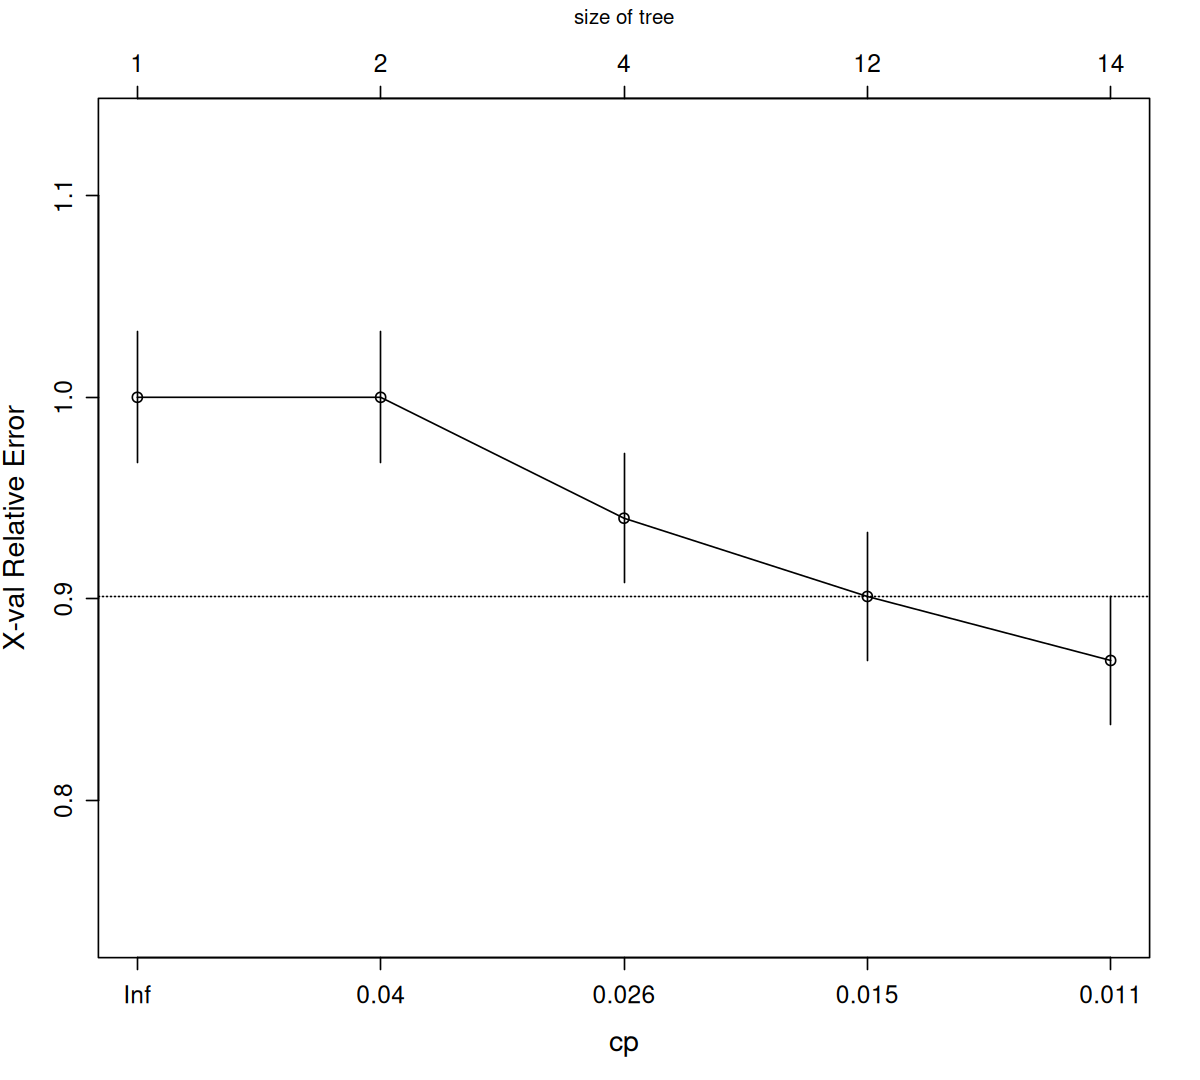

In [160]:
grafdim(10,9)
plotcp(mod_arv, cex.lab=1.4, cex.axis=1.2)

In [161]:
mod_pod <- prune(mod_arv, cp=0.02)

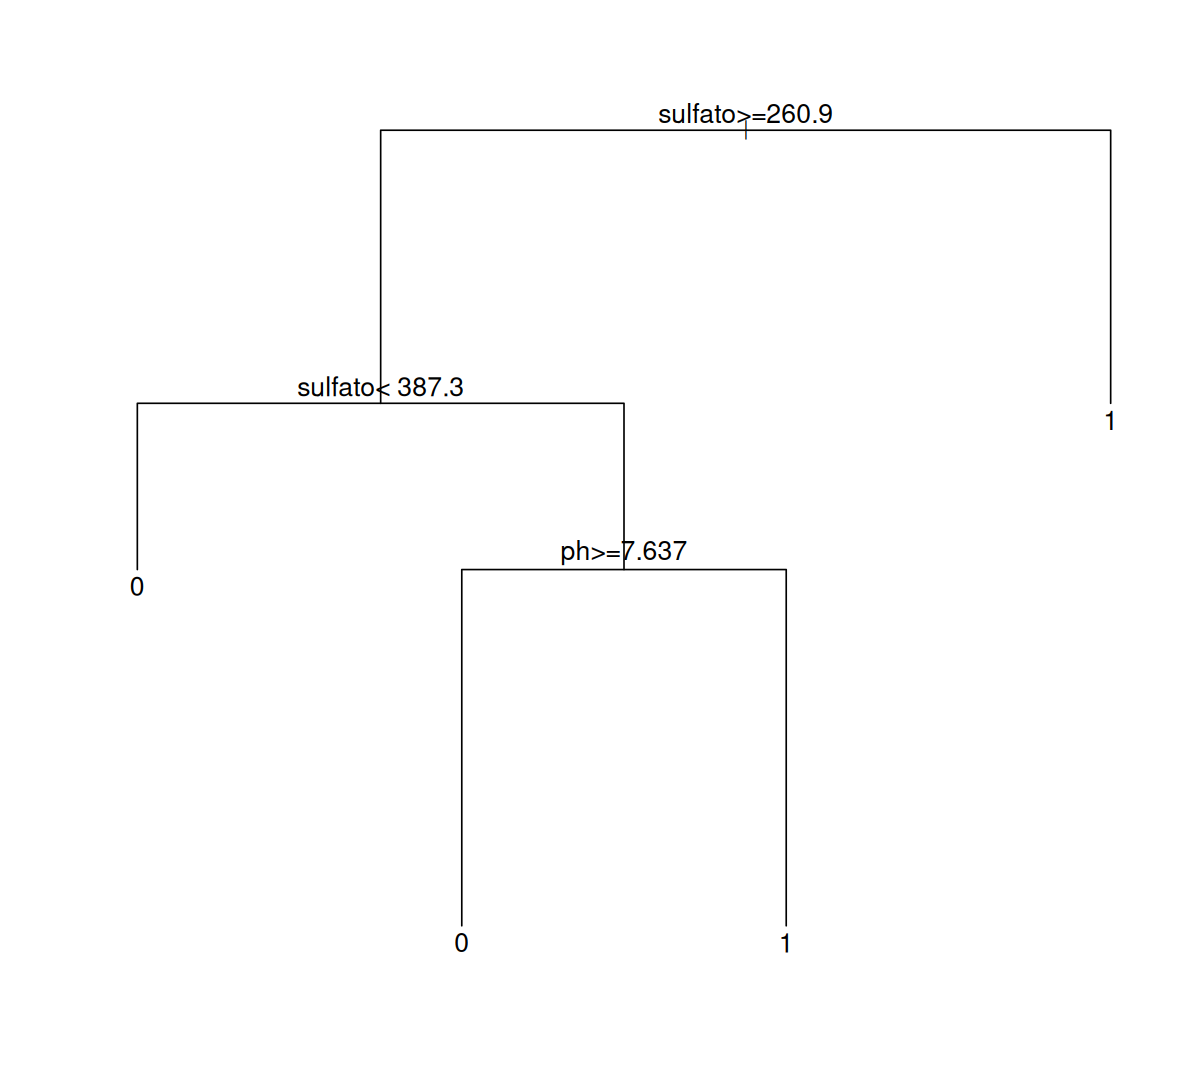

In [163]:
grafdim(10,9)
plot(mod_pod)
text(mod_pod, cex=1.3, xpd=TRUE)

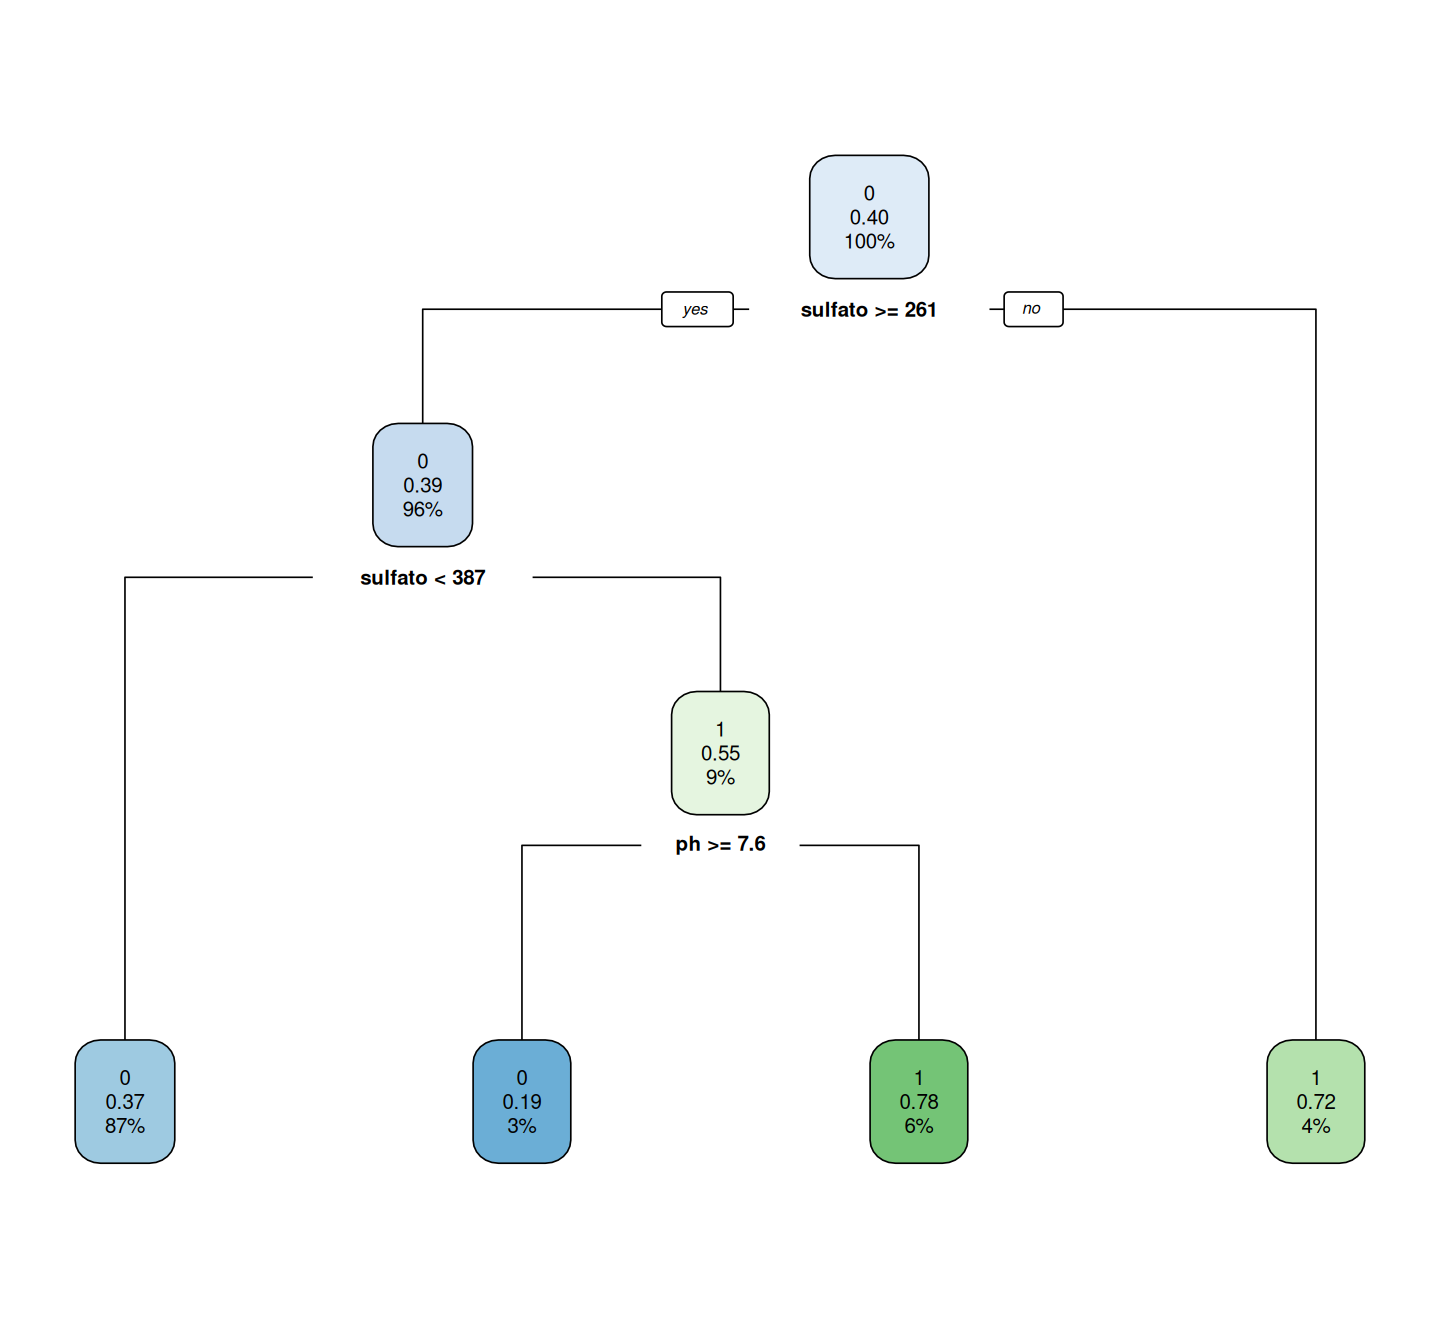

In [164]:
grafdim(12,11)
rpart.plot(mod_pod)

In [165]:
predito <- predict(mod_pod, treino, type="class")

In [166]:
str(predito)
str(treino$potavel)

 Factor w/ 2 levels "0","1": 1 1 1 1 1 1 1 1 1 1 ...
 - attr(*, "names")= chr [1:1409] "4" "6" "7" "10" ...
 int [1:1409] 0 0 0 0 0 0 0 0 0 0 ...


In [167]:
print(head(predito,25))

 4  6  7 10 13 16 18 20 25 27 33 34 37 40 44 47 50 52 53 54 55 57 58 62 67 
 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  1  0  0  0  0  0  0  0 
Levels: 0 1


In [168]:
(mat_confus <- confusionMatrix(data=predito, reference=factor(treino$potavel), positive="1"))

Confusion Matrix and Statistics

          Reference
Prediction   0   1
         0 809 467
         1  33 100
                                      
               Accuracy : 0.645       
                 95% CI : (0.62, 0.67)
    No Information Rate : 0.598       
    P-Value [Acc > NIR] : 0.000138    
                                      
                  Kappa : 0.157       
                                      
 Mcnemar's Test P-Value : < 2e-16     
                                      
            Sensitivity : 0.1764      
            Specificity : 0.9608      
         Pos Pred Value : 0.7519      
         Neg Pred Value : 0.6340      
             Prevalence : 0.4024      
         Detection Rate : 0.0710      
   Detection Prevalence : 0.0944      
      Balanced Accuracy : 0.5686      
                                      
       'Positive' Class : 1           
                                      

In [169]:
(mod_pod_treino_acbal <- mat_confus$byClass["Balanced Accuracy"])

Balanced Accuracy 
            0.569

In [170]:
tabela <- as.data.frame(mat_confus$table)
tabela$Reference <- factor(tabela$Reference, levels=rev(levels(tabela$Reference)))
tabela

Prediction,Reference,Freq
<fct>,<fct>,<int>
0,0,809
1,0,33
0,1,467
1,1,100


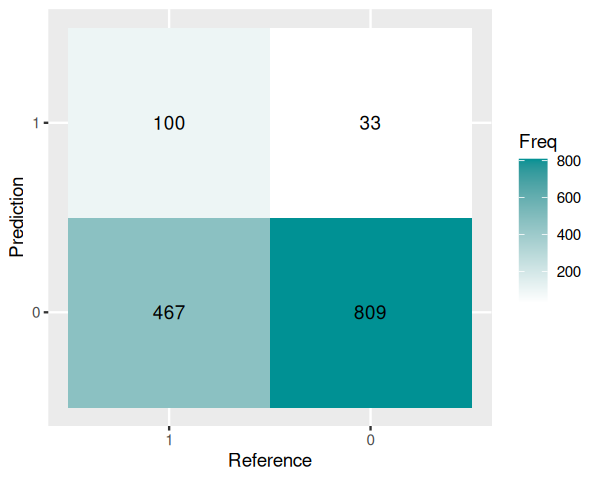

In [171]:
grafdim(5,4)
ggplot(tabela, aes(Reference, Prediction, fill=Freq)) +
        geom_tile() + geom_text(aes(label=Freq)) +
        scale_fill_gradient(low="white", high="#009194") +
        labs(x="Reference",y="Prediction" )

In [172]:
predito <- predict(mod_pod, new=valid, type="class")

In [173]:
(mat_confus <- confusionMatrix(data=predito, reference=factor(valid$potavel), positive="1"))

Confusion Matrix and Statistics

          Reference
Prediction   0   1
         0 178  96
         1   8  19
                                        
               Accuracy : 0.654         
                 95% CI : (0.598, 0.708)
    No Information Rate : 0.618         
    P-Value [Acc > NIR] : 0.106         
                                        
                  Kappa : 0.143         
                                        
 Mcnemar's Test P-Value : <2e-16        
                                        
            Sensitivity : 0.1652        
            Specificity : 0.9570        
         Pos Pred Value : 0.7037        
         Neg Pred Value : 0.6496        
             Prevalence : 0.3821        
         Detection Rate : 0.0631        
   Detection Prevalence : 0.0897        
      Balanced Accuracy : 0.5611        
                                        
       'Positive' Class : 1             
                                        

In [174]:
(mod_pod_valid_acbal <- mat_confus$byClass["Balanced Accuracy"])

Balanced Accuracy 
            0.561

## Modelo com ponderação

A ponderação ocorre quando a proporção de casos positivos é muito pequena (menor que 30%?) com relação à classe negativa.  
O peso de uma classe é a proporção da outra.

In [175]:
# construindo um vetor com o mesmo número do posições que observações em treino
pesos <- numeric(nrow(treino)) 

(npos <- sum(treino$potavel == 1))
(nneg <- sum(treino$potavel == 0))
(n    <- npos + nneg)
nrow(treino)

[1] 567

[1] 842

[1] 1409

[1] 1409

In [176]:
(ppos   <- nneg / n) # o peso do positivo é a proporção do negativo
(pneg   <- npos / n) # e vice-versa

[1] 0.598

[1] 0.402

In [177]:
pesos <- ifelse(treino$potavel == 0, pneg, ppos)

In [178]:
mod_pes <- rpart(potavel ~ . , data=treino, 
                 method="class",
                 weight=pesos,
                 minsplit=20, minbucket=7, maxdepth=30)

In [179]:
printcp(mod_pes)


Classification tree:
rpart(formula = potavel ~ ., data = treino, weights = pesos, 
    method = "class", minsplit = 20, minbucket = 7, maxdepth = 30)

Variables actually used in tree construction:
[1] carbono_org cloramina   dureza      ph          solido      sulfato    

Root node error: 339/1409 = 0.2

n= 1409 

     CP nsplit rel error xerror xstd
1  0.05      0       1.0    1.1 0.04
2  0.04      1       1.0    1.0 0.04
3  0.03      4       0.8    0.9 0.04
4  0.03      6       0.7    0.9 0.04
5  0.02      7       0.7    0.8 0.04
6  0.02      8       0.7    0.8 0.04
7  0.01      9       0.7    0.8 0.04
8  0.01     10       0.7    0.8 0.04
9  0.01     11       0.6    0.8 0.04
10 0.01     14       0.6    0.8 0.04
11 0.01     15       0.6    0.8 0.04


In [180]:
print(mod_pes$variable.importance)

      sulfato            ph        dureza     cloramina        solido 
       25.046        15.369        12.668         8.990         6.980 
  carbono_org condutividade      turbidez trihalometano 
        2.372         1.518         0.941         0.797 


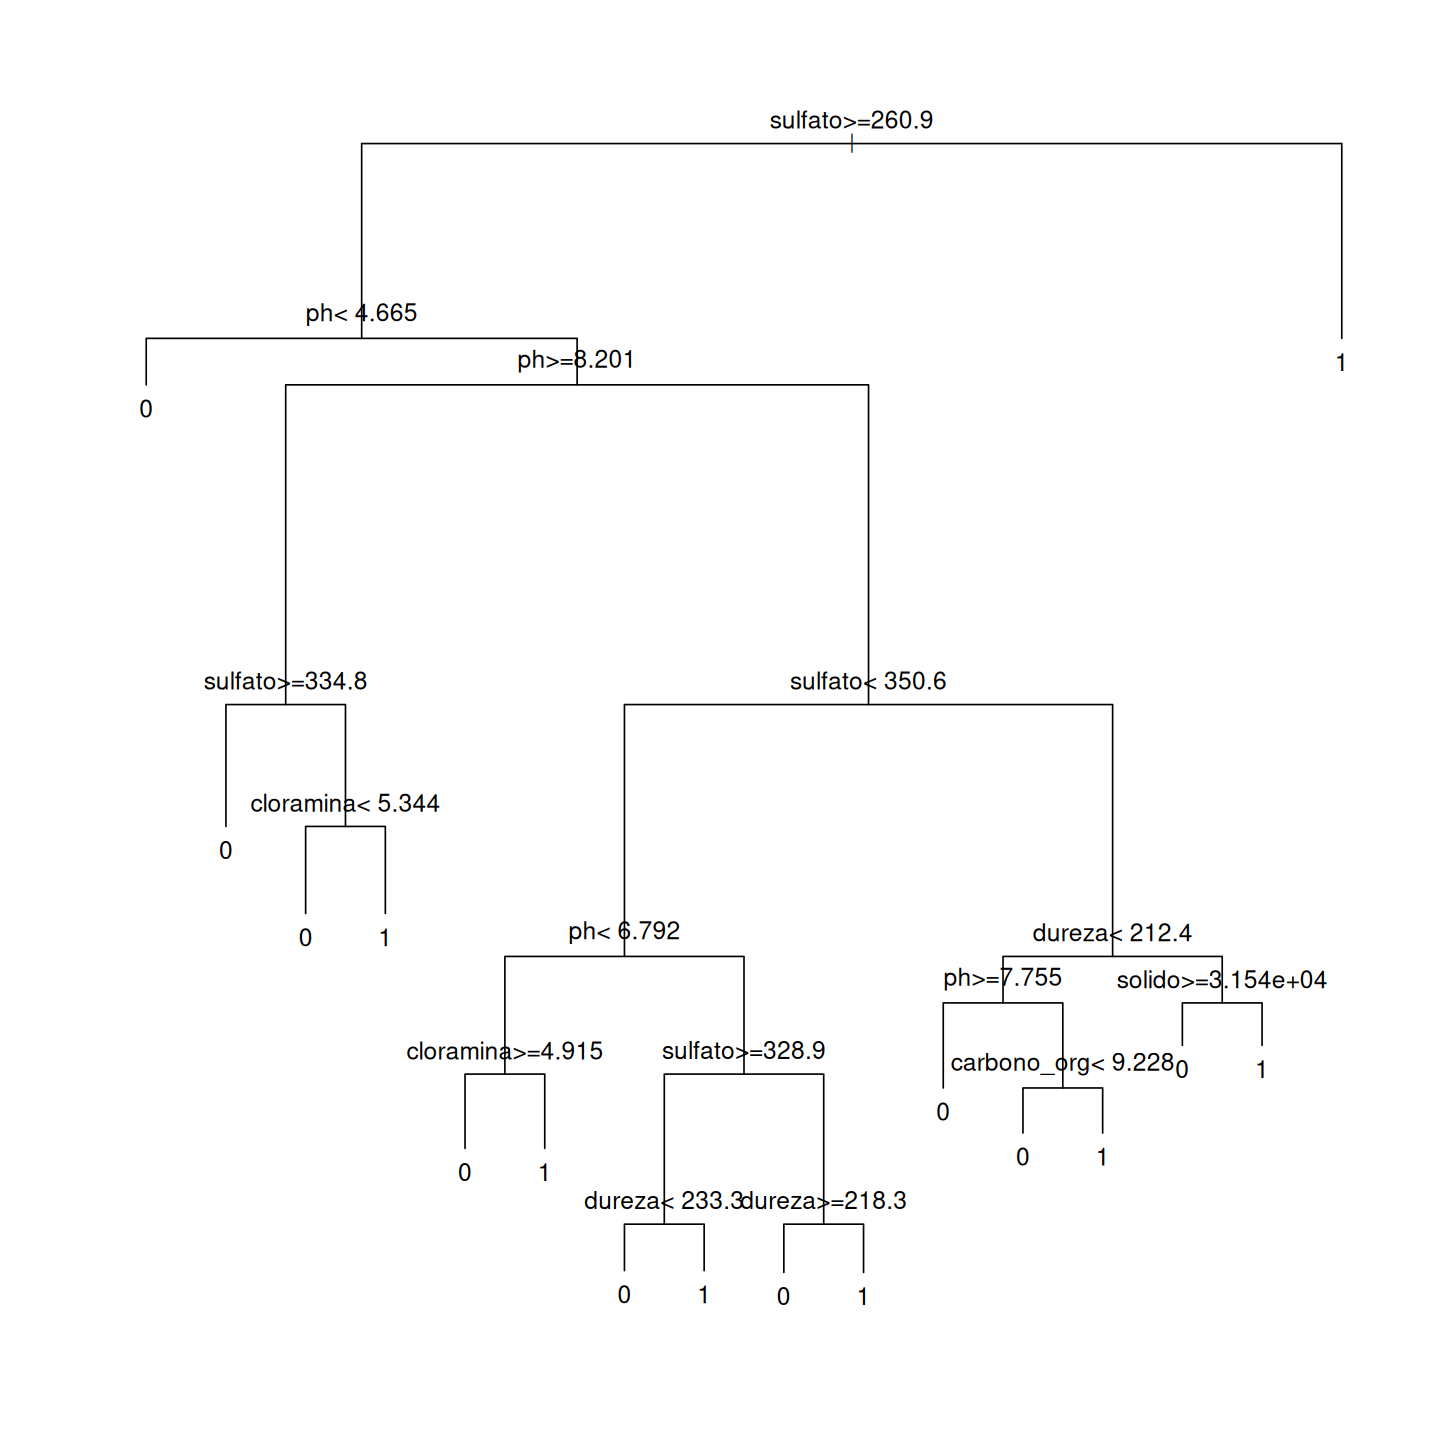

In [181]:
grafdim(12,12)
plot(mod_pes)
text(mod_pes, cex=1.2, xpd=TRUE)

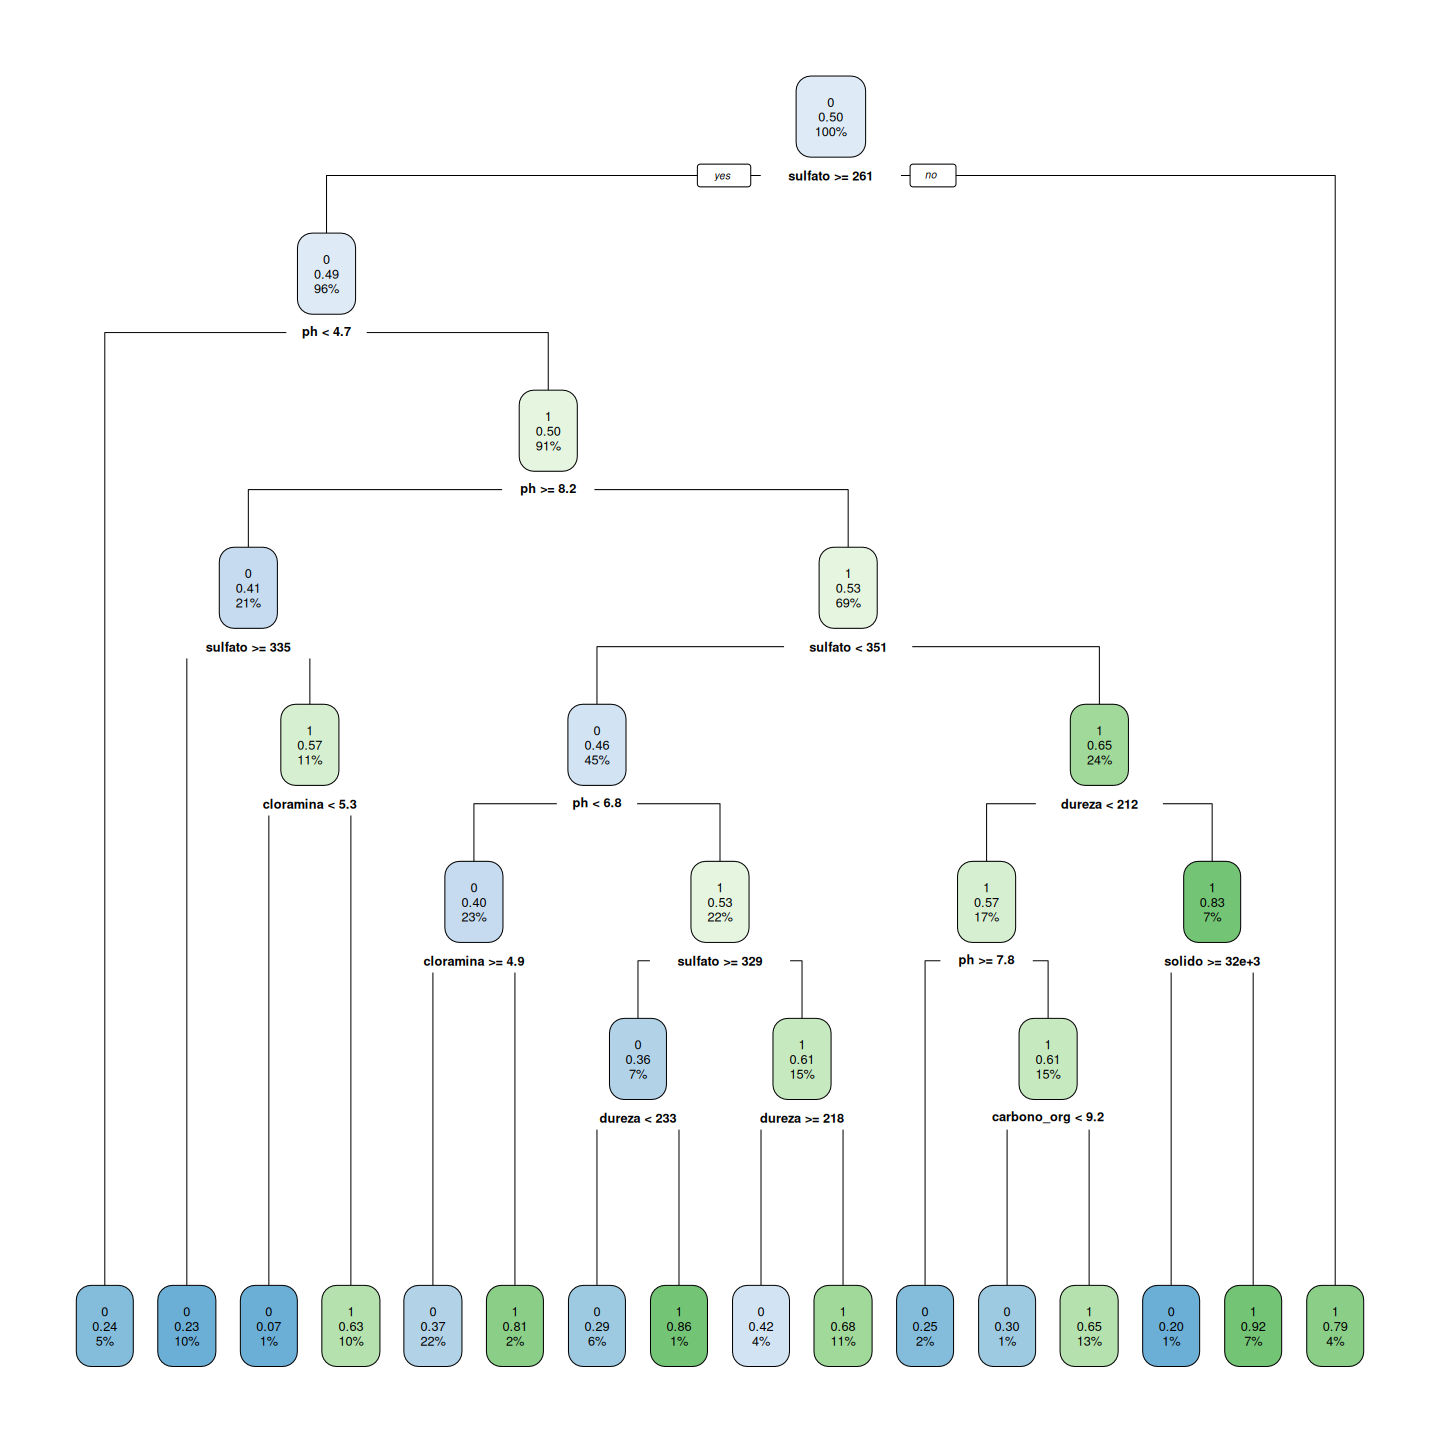

In [182]:
rpart.plot(mod_pes)

In [183]:
predito <- predict(mod_pes, treino, type="class")

In [184]:
(mat_confus <- confusionMatrix(data=predito, reference=factor(treino$potavel), positive="1"))

Confusion Matrix and Statistics

          Reference
Prediction   0   1
         0 609 183
         1 233 384
                                       
               Accuracy : 0.705        
                 95% CI : (0.68, 0.728)
    No Information Rate : 0.598        
    P-Value [Acc > NIR] : <2e-16       
                                       
                  Kappa : 0.395        
                                       
 Mcnemar's Test P-Value : 0.0163       
                                       
            Sensitivity : 0.677        
            Specificity : 0.723        
         Pos Pred Value : 0.622        
         Neg Pred Value : 0.769        
             Prevalence : 0.402        
         Detection Rate : 0.273        
   Detection Prevalence : 0.438        
      Balanced Accuracy : 0.700        
                                       
       'Positive' Class : 1            
                                       

In [185]:
(mod_pes_treino_acbal <- mat_confus$byClass["Balanced Accuracy"])

Balanced Accuracy 
              0.7

In [186]:
predito <- predict(mod_pes, new=valid, type="class")

In [187]:
(mat_confus <- confusionMatrix(data=predito, reference=factor(valid$potavel), positive="1"))

Confusion Matrix and Statistics

          Reference
Prediction   0   1
         0 117  55
         1  69  60
                                       
               Accuracy : 0.588        
                 95% CI : (0.53, 0.644)
    No Information Rate : 0.618        
    P-Value [Acc > NIR] : 0.870        
                                       
                  Kappa : 0.147        
                                       
 Mcnemar's Test P-Value : 0.243        
                                       
            Sensitivity : 0.522        
            Specificity : 0.629        
         Pos Pred Value : 0.465        
         Neg Pred Value : 0.680        
             Prevalence : 0.382        
         Detection Rate : 0.199        
   Detection Prevalence : 0.429        
      Balanced Accuracy : 0.575        
                                       
       'Positive' Class : 1            
                                       

In [188]:
(mod_pes_valid_acbal <- mat_confus$byClass["Balanced Accuracy"])

Balanced Accuracy 
            0.575